# Steam Games Catalog Analysis
## Project Phase 1: Data Understanding and Preprocessing

## Section 1: Group Details and Setup

**Dataset:** Steam Games Dataset from Kaggle, saved as `steam_games_raw.csv`, 125,855 games × 40 columns

| Name | Roll no. |
|---|---|
| Maaz Ahmed Khan | CT-24076 |

**Problem statement:** Steam hosts over 100,000 games, yet outcomes vary enormously, and developers have little guidance on which pre-release decisions actually matter. This project analyzes the Steam catalog to identify how price, genre, platform support, language support, publisher, and release timing relate to a game's review score, among games with at least 50 reviews.

**Target (y):** `Review score` = Positive / (Positive + Negative), a continuous value between 0 and 1, so this is a **regression** problem.

**Notebook map**

| Notebook section | Assignment task |
|---|---|
| Section 1: Group Details and Setup | 1. Group details and notebook setup |
| Section 2: Data Loading and Feature Understanding | 2. Explain every feature, identify the target |
| Section 3: Data Quality Issues | 3. Identify data quality issues |
| Section 4: Data Cleaning | 4. Basic data cleaning, 8. Save files |
| Section 5: Exploratory Analysis and Insights | 2. Graphs, statistics, insights, separate X and y |
| Section 6: Train-Test Split | 5. Split the dataset |
| Section 7: Preprocessing and Feature Selection | 6. Preprocessing and feature selection |
| Section 8: Class Imbalance | 7. Check class imbalance (not applicable) |
| Section 9: Limitations | Limits of the data and approach |
| Section 10: Bonus Work | 10. Bonus marks |
| Section 11: Problem Definition | Phase 2: 1. Define the problem |
| Section 12: Model Training and Cross-Validation | Phase 2: 2. Train multiple models |
| Section 13: Model Comparison | Phase 2: 3. Evaluate and compare models |
| Section 14: Hyperparameter Tuning | Phase 2: 4. Hyperparameter tuning |
| Section 15: Final Evaluation and Discussion | Phase 2: 5. Results and discussion |

### Imports

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

## Section 2: Data Loading and Feature Understanding

### Loading the data

The raw CSV has a broken header. Two column names, `Discount` and `DLC count`, are merged into a single field, `DiscountDLC count`. So the header has **39** names while each row has **40** values, which shifts every column after it.

**Fix:** read the header, split the merged name back into two, then load the data with the corrected names.

In [2]:
cols = pd.read_csv('steam_games_raw.csv', nrows=0).columns.tolist()
print('Header fields:', len(cols))

i = cols.index('DiscountDLC count')
cols[i:i+1] = ['Discount', 'DLC count']

df_raw = pd.read_csv('steam_games_raw.csv', header=None, skiprows=1, names=cols)
df = df_raw.copy()
print('Shape:', df.shape)

Header fields: 39
Shape: (125855, 40)


### Data overview

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 125855 entries, 0 to 125854
Data columns (total 40 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   AppID                       125855 non-null  int64  
 1   Name                        125854 non-null  str    
 2   Release date                125855 non-null  str    
 3   Estimated owners            125855 non-null  str    
 4   Peak CCU                    125855 non-null  int64  
 5   Required age                125855 non-null  int64  
 6   Price                       125855 non-null  float64
 7   Discount                    125855 non-null  int64  
 8   DLC count                   125855 non-null  int64  
 9   About the game              117393 non-null  str    
 10  Supported languages         125855 non-null  str    
 11  Full audio languages        125855 non-null  str    
 12  Reviews                     12181 non-null   str    
 13  Header image             

In [4]:
df.describe(include='all')

,AppID,Name,Release date,Estimated owners,Peak CCU,Required age,Price,Discount,DLC count,About the game,Supported languages,Full audio languages,Reviews,Header image,Website,Support url,Support email,Windows,Mac,Linux,Metacritic score,Metacritic url,User score,Positive,Negative,Score rank,Achievements,Recommendations,Notes,Average playtime forever,Average playtime two weeks,Median playtime forever,Median playtime two weeks,Developers,Publishers,Categories,Genres,Tags,Screenshots,Movies
count,1.258550e+05,125854,125855,125855,1.258550e+05,125855.000000,125855.000000,125855.000000,125855.000000,117393,125855,125855,12181,125774,50520,55295,103225,125855,125855,125855,125855.000000,4258,125855.000000,1.258550e+05,1.258550e+05,40.000000,125855.000000,1.258550e+05,23310,1.258550e+05,125855.000000,1.258550e+05,125855.000000,117406,116933,116889,117432,83353,119828,0.0
unique,NaN,124644,5141,14,NaN,NaN,NaN,NaN,NaN,116776,19614,3785,11987,125664,40353,36161,62321,2,2,2,NaN,4162,NaN,NaN,NaN,NaN,NaN,NaN,19332,NaN,NaN,NaN,NaN,72859,64607,14058,2922,77184,119718,NaN
top,NaN,Shadow of the Tomb Raider: Definitive Edition,"Oct 23, 2025",0 - 20000,NaN,NaN,NaN,NaN,NaN,Help the beautiful girls to immerse themselves...,['English'],[],"“🏆 I loved! ❤️❤️❤️” Player “🏆 Cute kittens, ea...",https://shared.akamai.steamstatic.com/store_it...,https://www.facebook.com/8FloorGames/,https://www.facebook.com/8FloorGames,info@bigfishgames.com,True,False,False,NaN,https://www.metacritic.com/game/pc/shadow-of-t...,NaN,NaN,NaN,NaN,NaN,NaN,This Game may contain content not appropriate ...,NaN,NaN,NaN,NaN,EroticGamesClub,BFG Entertainment,"Single-player,Family Sharing","Casual,Indie","Adventure,Casual,Hidden Object",https://shared.akamai.steamstatic.com/store_it...,NaN
freq,NaN,20,190,75705,NaN,NaN,NaN,NaN,NaN,65,56690,74622,47,20,274,331,323,125811,104136,109786,NaN,20,NaN,NaN,NaN,NaN,NaN,NaN,189,NaN,NaN,NaN,NaN,232,554,23878,6912,273,20,NaN
mean,2.032627e+06,NaN,NaN,NaN,5.318720e+01,0.165365,4.811174,17.896826,0.535434,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.500083,NaN,0.023916,1.018182e+03,1.648786e+02,99.175000,17.922220,9.380399e+02,NaN,2.027568e+02,13.507711,1.691803e+02,14.419125,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,1.117434e+06,NaN,NaN,NaN,3.681083e+03,1.642666,12.489329,28.628518,14.328417,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13.492922,NaN,1.376811,2.772782e+04,5.305001e+03,0.675107,139.696425,2.159585e+04,NaN,1.107222e+04,266.925759,1.105725e+04,290.747134,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000000e+01,NaN,NaN,NaN,0.000000e+00,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000,0.000000e+00,0.000000e+00,98.000000,0.000000,0.000000e+00,NaN,0.000000e+00,0.000000,0.000000e+00,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,1.083495e+06,NaN,NaN,NaN,0.000000e+00,0.000000,0.590000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000,0.000000e+00,0.000000e+00,99.000000,0.000000,0.000000e+00,NaN,0.000000e+00,0.000000,0.000000e+00,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,1.949010e+06,NaN,NaN,NaN,0.000000e+00,0.000000,2.390000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000,4.000000e+00,1.000000e+00,99.000000,2.000000,0.000000e+00,NaN,0.000000e+00,0.000000,0.000000e+00,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,2.938410e+06,NaN,NaN,NaN,0.000000e+00,0.000000,5.545000,37.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000,3.500000e+01,1.000000e+01,100.000000,19.000000,0.000000e+00,NaN,0.000000e+00,0.000000,0.000000e+00,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
df.sample(5, random_state=42)

,AppID,Name,Release date,Estimated owners,Peak CCU,Required age,Price,Discount,DLC count,About the game,Supported languages,Full audio languages,Reviews,Header image,Website,Support url,Support email,Windows,Mac,Linux,Metacritic score,Metacritic url,User score,Positive,Negative,Score rank,Achievements,Recommendations,Notes,Average playtime forever,Average playtime two weeks,Median playtime forever,Median playtime two weeks,Developers,Publishers,Categories,Genres,Tags,Screenshots,Movies
127,3400080,Fantasy Soul Revenge,"Dec 28, 2024",0 - 20000,0,0,0.69,0,0,Fantasy Soul Revenge - Explore Your Fighting S...,"['English', 'French', 'Italian', 'German', 'Sp...",[],NaN,https://shared.akamai.steamstatic.com/store_it...,NaN,NaN,nitin.javapro@gmail.com,True,False,False,0,NaN,0,4,2,NaN,0,0,NaN,0,0,0,0,Nitx Games,Nitx Games,"Single-player,Family Sharing","Action,Casual,Indie,Simulation,Strategy","Side Scroller,Action,Beat 'em up,2D Fighter,Ar...",https://shared.akamai.steamstatic.com/store_it...,NaN
67814,2554950,Raioh,"Oct 6, 2023",0 - 20000,0,0,3.49,50,0,Raioh is a retro style shot and bomb style ver...,['English'],[],NaN,https://shared.akamai.steamstatic.com/store_it...,NaN,NaN,ontake44@gmail.com,True,False,False,0,NaN,0,17,0,NaN,0,0,NaN,0,0,0,0,Ontake Workshop,Ontake Workshop,"Single-player,Partial Controller Support,Famil...",Action,"Action,Shooter,Shoot 'Em Up,Singleplayer,2D,Pi...",https://shared.akamai.steamstatic.com/store_it...,NaN
29650,4025190,Ten Tek,"Oct 18, 2025",0 - 0,0,0,1.59,0,0,TenTek is an atmospheric mystical game where y...,"['English', 'Russian']","['English', 'Russian']",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN,NaN,lgcompanymonitors@gmail.com,True,False,False,0,NaN,0,0,0,NaN,0,118,The game contains scenes of full nudity and ex...,0,0,0,0,Inspite,Inspite,"Single-player,Family Sharing","Indie,Simulation",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
104535,472770,HELP: THE GAME,"Jul 26, 2016",0 - 20000,0,0,14.99,0,0,HELP: The Game is a project which brings toget...,['English'],['English'],NaN,https://shared.akamai.steamstatic.com/store_it...,https://warchildgaming.org.uk/campaign/help-pc...,https://warchildgaming.org.uk/campaign/help-pc...,NaN,True,False,False,0,NaN,0,9,0,NaN,0,0,NaN,0,0,0,0,"Sports Interactive,Creative Assembly,Rovio Swe...",War Child Gaming,"Single-player,Multi-player,Partial Controller ...",Indie,Indie,https://shared.akamai.steamstatic.com/store_it...,NaN
51049,4129210,Hentai Travel,"Nov 21, 2025",0 - 0,0,0,2.99,0,0,Hentai Travel - Solve puzzles of varying diffi...,"['English', 'French', 'Italian', 'German', 'Sp...",[],NaN,https://shared.akamai.steamstatic.com/store_it...,NaN,NaN,uwuGameDEVelop@gmail.com,True,False,False,0,NaN,0,0,0,NaN,30,0,-Nudity sexual content -Not suitable for all a...,0,0,0,0,UwU,UwU,"Single-player,Steam Achievements,Full controll...","Casual,Indie",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN


### Column descriptions

| Column | Description | Decision |
|---|---|---|
| AppID | Unique Steam ID of the game | Used for duplicate checks, then dropped (identifier) |
| Name | Game title | Used for duplicate checks, then dropped (identifier) |
| Release date | Release date, stored as text | **Keep**. Parsed to datetime; Year and Month extracted |
| Estimated owners | Owner range, e.g. `20000 - 50000` | Converted to `Owner Rank`, then dropped. Post-release outcome, used for EDA only |
| Peak CCU | Peak concurrent players | Drop. Post-release metric |
| Required age | Minimum age gate | Drop. ~99% of values are 0 |
| Price | Price in USD (0 = free) | **Keep**. Key pre-release decision |
| Discount | Current discount % | Drop. Post-release, mostly 0 |
| DLC count | Number of DLCs | Drop. Post-release (most DLC is released after launch) |
| About the game | Long description text | Drop. Free text; Genres/Categories already capture the content |
| Supported languages | Interface/subtitle languages (list) | **Keep**. Converted to `Language count` and `Supports english` |
| Full audio languages | Fully voiced languages (list) | **Keep**. Converted to `Full audio count` |
| Reviews | Press review quotes | Drop. ~90% missing |
| Header image, Website, Support url, Support email, Screenshots, Movies, Metacritic url | Links / contact info | Drop. No analytical value (`Movies` is completely empty) |
| Windows | Windows support (True/False) | Drop. True for almost every game |
| Mac / Linux | Platform support (True/False) | **Keep** |
| Metacritic score | Critic score (0 = not reviewed) | Drop. Mostly 0, post-release |
| User score | User score (0 = none) | Drop. Almost entirely 0 |
| Positive / Negative | Number of positive / negative Steam reviews | **Keep**. Used to build the target; never used as features |
| Score rank | Ranking by score | Drop. Mostly missing, post-release |
| Achievements | Number of achievements | Drop. Minimal relevance to the target |
| Recommendations | Number of recommendations | Drop. Post-release |
| Notes | Content warnings text | Drop. Mostly missing |
| Average / Median playtime (forever, two weeks) | Playtime stats | Drop. Post-release, mostly 0 |
| Developers / Publishers | Studio and publisher names | **Keep**. Encoded after the train/test split |
| Categories | Steam feature labels (Single-player, Co-op, ...) | **Keep**. Grouped into 10 `Cat:` flags |
| Genres | Game genres | **Keep**. Converted to `Genre:` flags |
| Tags | User-applied tags | Drop. Voted on by players after release |

### Identifying the target

**Target (y): `Review score`** = Positive / (Positive + Negative), the share of a game's Steam reviews that are positive. It is a continuous value between 0 and 1, so this is a **regression** problem.

**Why this target:** the review score is the clearest measure of how well a game is received by its players, and it is the outcome a developer cares about when making pre-release decisions. Filtering to games with at least 50 reviews (Section 4) makes the score stable enough to predict.

**What is kept out of X:** only information a developer knows *before* release is used as a feature. `Positive`, `Negative` and `Total reviews` are used to build y, so they cannot be features. `Owner Rank`, playtime, recommendations and similar columns are post-release outcomes driven by the same success the target measures, so including them would leak the answer into the features.

X and y are separated at the end of Section 5, after cleaning and exploration.

## Section 3: Data Quality Issues

Each issue is shown here with a table, graph or statistic. The fixes are applied in Section 4.

### Missing values

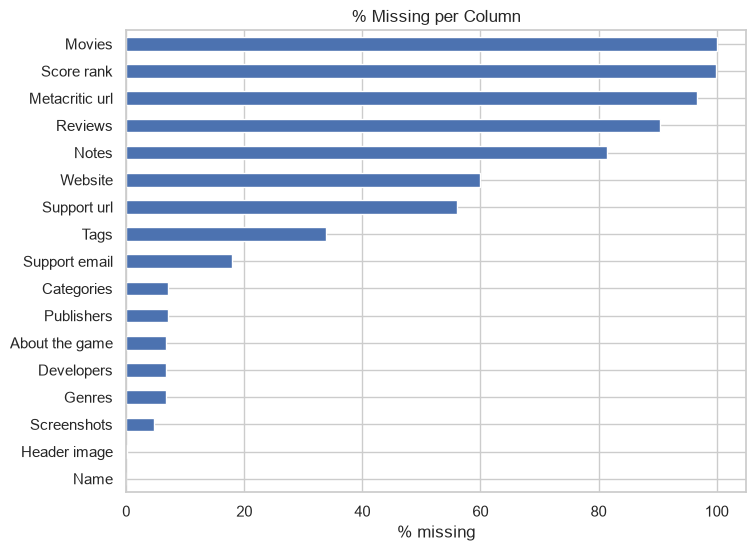

In [6]:
missing = (df.isnull().mean() * 100).sort_values(ascending=False)
missing = missing[missing > 0]

missing.plot(kind='barh', figsize=(8, 6), title='% Missing per Column')
plt.xlabel('% missing')
plt.gca().invert_yaxis()
plt.show()

- `Movies`, `Reviews`, `Score rank`, `Notes` and `Metacritic url` are more than 80% empty, so there is nothing to impute from.
- **Tags** is missing for about a third of games.
- **Developers, Publishers, Categories, Genres** are each missing for about 7%.
- One game has no **Name**.

### Columns that are mostly zero

Some numeric columns have no missing values but are almost entirely 0. Here, 0 effectively means "no data".

In [7]:
zero_cols = ['User score', 'Metacritic score', 'Required age', 'Peak CCU','Average playtime forever', 'Achievements', 'Recommendations','DLC count', 'Discount']

zero_share = (df[zero_cols] == 0).mean().mul(100).round(2).sort_values(ascending=False)
zero_share

User score                  99.97
Required age                98.98
Metacritic score            96.62
DLC count                   85.67
Peak CCU                    84.36
Recommendations             83.30
Average playtime forever    79.20
Discount                    67.57
Achievements                48.57
dtype: float64

Apart from being largely zero, most of these columns are **post-release** metrics: they are only known after the game is out. The project is about decisions made *before* release, so they are dropped in Section 4.

### Duplicates

In [8]:
print('Fully duplicated rows:', df.duplicated().sum())
print('Duplicated AppIDs    :', df['AppID'].duplicated().sum())
print('Duplicated Names     :', df['Name'].duplicated().sum())

Fully duplicated rows: 0
Duplicated AppIDs    : 0
Duplicated Names     : 1210


In [9]:
df['Name'].value_counts().head(5)

Name
Shadow of the Tomb Raider: Definitive Edition    20
Escape                                            6
Loop                                              5
Gravity                                           5
Echoes                                            5
Name: count, dtype: int64

In [10]:
df.loc[df['Name'] == 'Shadow of the Tomb Raider: Definitive Edition',['AppID', 'Name', 'Release date', 'Price', 'Positive', 'Negative']].head(10)

,AppID,Name,Release date,Price,Positive,Negative
67,849178,Shadow of the Tomb Raider: Definitive Edition,"Sep 14, 2018",4.0,13036,4825
1179,849165,Shadow of the Tomb Raider: Definitive Edition,"Sep 14, 2018",4.0,10646,4341
1608,750920,Shadow of the Tomb Raider: Definitive Edition,"Sep 14, 2018",4.0,66684,12759
3621,849163,Shadow of the Tomb Raider: Definitive Edition,"Sep 14, 2018",4.0,10785,4398
27396,890030,Shadow of the Tomb Raider: Definitive Edition,"Sep 14, 2018",4.0,12819,4747
30140,849200,Shadow of the Tomb Raider: Definitive Edition,"Sep 14, 2018",4.0,12657,4677
32515,849176,Shadow of the Tomb Raider: Definitive Edition,"Sep 14, 2018",4.0,11036,4467
43881,849166,Shadow of the Tomb Raider: Definitive Edition,"Sep 14, 2018",4.0,11068,4489
47651,849161,Shadow of the Tomb Raider: Definitive Edition,"Sep 14, 2018",4.0,12577,4653
56776,849177,Shadow of the Tomb Raider: Definitive Edition,"Sep 14, 2018",4.0,12734,4710


There are no exact duplicate rows or AppIDs, but **1,210 names repeat**. For example, *Shadow of the Tomb Raider: Definitive Edition* appears 20 times with different AppIDs and the same release date. One listing has about 79k reviews, while the others each show about 15–18k. All of these AppIDs redirect to the same store page, so they are alternate listings of one game, not separate games.

### Incorrect data types and formats

**Release date** is stored as text. Every value follows one of two patterns:

In [11]:
shapes = (df['Release date'].astype(str)
          .str.replace(r'\d', '9', regex=True)
          .str.replace(r'[A-Za-z]', 'A', regex=True))
shapes.value_counts()

Release date
AAA 99, 9999    90462
AAA 9, 9999     35393
Name: count, dtype: int64

All dates are in `Mon D, YYYY` format (e.g. `Sep 14, 2018`), so they can be parsed into a proper datetime.

**Estimated owners** is a text range, not a number:

In [12]:
df['Estimated owners'].value_counts()

Estimated owners
0 - 20000                75705
0 - 0                    24579
20000 - 50000            11397
50000 - 100000            5355
100000 - 200000           3454
200000 - 500000           2856
500000 - 1000000          1155
1000000 - 2000000          729
2000000 - 5000000          405
5000000 - 10000000         125
10000000 - 20000000         51
20000000 - 50000000         31
50000000 - 100000000         9
100000000 - 200000000        4
Name: count, dtype: int64

**Language columns** hold Python-style lists stored as plain strings (e.g. `"['English', 'French']"`), which gives a huge number of unique values:

In [13]:
print('Unique Supported languages :', df['Supported languages'].nunique())
print('Unique Full audio languages:', df['Full audio languages'].nunique())
df['Supported languages'].value_counts().head(5)

Unique Supported languages : 19614
Unique Full audio languages: 3785


Supported languages
['English']                          56690
[]                                    8391
['English', 'Russian']                2789
['Simplified Chinese']                2622
['English', 'Simplified Chinese']     2364
Name: count, dtype: int64

### Disguised missing and inconsistent values

First **Estimated owners**:

In [14]:
print((df['Estimated owners']=='0 - 0').mean()*100)

19.529617416868618


**19.5%** of games have `0 - 0` owners. These are dead or unreleased store entries.

Now **Supported languages**:

In [15]:
print((df['Supported languages']=='[]').sum())

8391


**8,391** games list no supported languages at all. Every released game supports at least one language, so an empty list here is a **missing value in disguise**.

Now **Full audio languages**:

In [16]:
print((df['Full audio languages']=='[]').mean()*100)

59.2920424297803


**59.3%** of games have an empty list. Unlike supported languages, this is usually **real**: many games, especially indie titles, have no voice-over. It is kept as a count of 0 in Section 4.

Now **Price**:

In [17]:
print((df['Price']==0).mean()*100)

21.18390210957054


**21.2%** of games have a price of 0. Many are genuinely free-to-play, but some are paid games that are no longer on sale (delisted or replaced by a newer edition), and their price was recorded as 0. This is investigated in Section 4.

Now **Platforms**:

In [18]:
df[['Windows','Mac','Linux']].describe()

,Windows,Mac,Linux
count,125855,125855,125855
unique,2,2,2
top,True,False,False
freq,125811,104136,109786


**Windows** is True for 125,811 of 125,855 games (99.97%). A near-constant column carries no information.

Now **category labels**. The same Steam feature appears under two different names:

In [19]:
category_labels = df['Categories'].str.split(',').explode()
category_labels[category_labels.isin(['VR Supported', 'VR Support', 'Mods', 'Mods (require HL2)'])].value_counts()

Categories
VR Supported          1206
VR Support             233
Mods (require HL2)       2
Mods                     2
Name: count, dtype: int64

"VR Supported" and "VR Support" mean the same thing, and so do "Mods" and "Mods (require HL2)". They are merged when categories are grouped in Section 4.

Finally, one **malformed language name**:

In [20]:
print(df['Supported languages'].str.contains("K'iche'", regex=False).sum())

2016


The language *K'iche'* contains apostrophes, and the dataset stores it **without quotes** (`..., 'Kinyarwanda', K'iche', 'Konkani', ...`). Python cannot read that as a list item, so these rows fail to parse until the value is fixed.

### Outliers

count    125855.000000
mean          4.811174
std          12.489329
min           0.000000
25%           0.590000
50%           2.390000
75%           5.545000
max         999.980000
Name: Price, dtype: float64

Skewness: 22.2


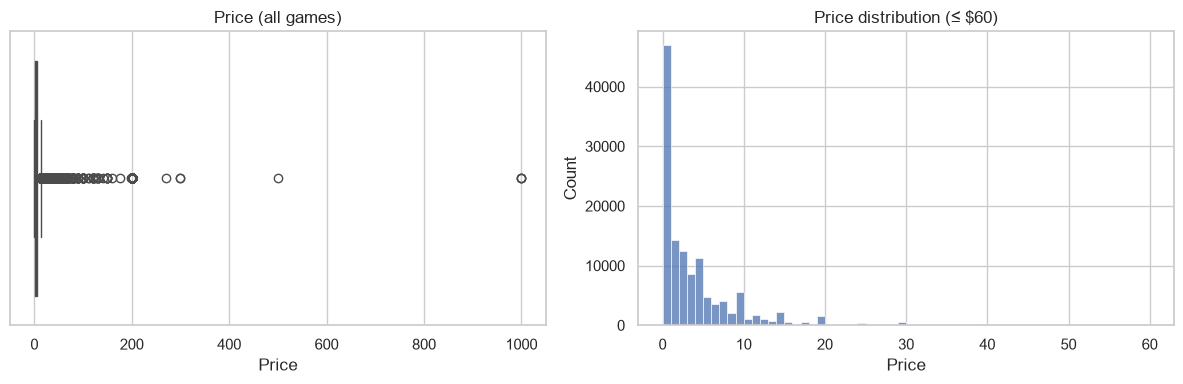

In [21]:
print(df['Price'].describe())
print('\nSkewness:', round(df['Price'].skew(), 2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df['Price'], ax=ax[0]).set_title('Price (all games)')
sns.histplot(df.loc[df['Price'] <= 60, 'Price'], bins=60, ax=ax[1]).set_title('Price distribution (≤ $60)')
plt.tight_layout()
plt.show()

In [22]:
expensive = df[df['Price'] > 100]
print('Games priced above $100:', len(expensive))
expensive[['Price', 'Positive', 'Negative']].describe()

Games priced above $100: 317


,Price,Positive,Negative
count,317.000000,317.000000,317.000000
mean,204.119748,5.078864,4.914826
std,82.381098,15.156257,8.164197
min,109.990000,0.000000,0.000000
25%,199.990000,0.000000,0.000000
50%,199.990000,0.000000,0.000000
75%,199.990000,7.000000,8.000000
max,999.980000,233.000000,46.000000


Price is extremely right-skewed (skew is almost 22, max 999.98 USD). The 317 games priced above 100 USD have a median of **0 reviews**, so most are joke listings rather than real premium games. The game priced at 999.98 USD is called `Congratulations On Your Purchase`; it is meant as a joke, not a real game.

           Positive      Negative
count  1.258550e+05  1.258550e+05
mean   1.018182e+03  1.648786e+02
std    2.772782e+04  5.305001e+03
min    0.000000e+00  0.000000e+00
25%    0.000000e+00  0.000000e+00
50%    4.000000e+00  1.000000e+00
75%    3.500000e+01  1.000000e+01
max    7.642084e+06  1.173003e+06


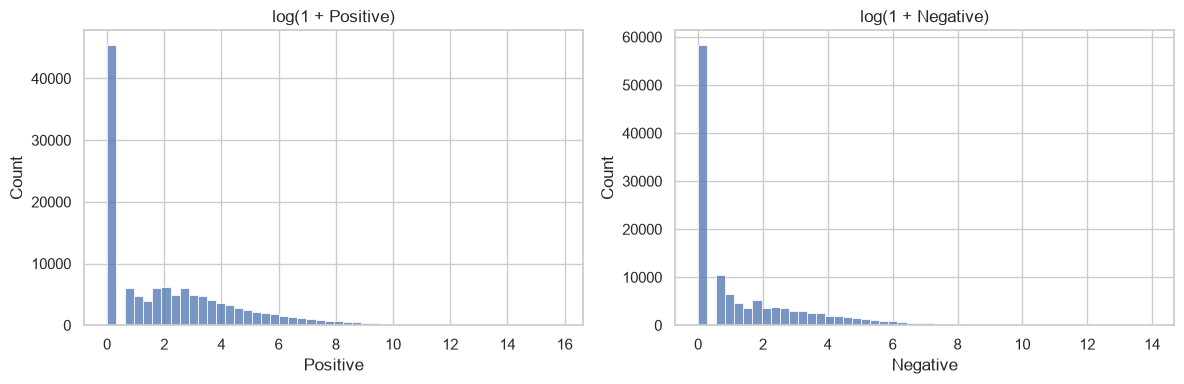

In [23]:
print(df[['Positive', 'Negative']].describe())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, col in zip(ax, ['Positive', 'Negative']):
    sns.histplot(np.log1p(df[col]), bins=50, ax=a).set_title(f'log(1 + {col})')
plt.tight_layout()
plt.show()

Review counts are very heavily skewed. The median game has only **4** positive reviews, while the largest has over 7.6 million. Most games have too few reviews for their review score to mean anything.

### High-cardinality categorical columns

In [24]:
df[['Developers', 'Publishers', 'Genres', 'Categories', 'Tags']].nunique()

Developers    72859
Publishers    64607
Genres         2922
Categories    14058
Tags          77184
dtype: int64

In [25]:
df['Genres'].value_counts().head(10)

Genres
Casual,Indie              6912
Action,Indie              5802
Action,Adventure,Indie    5259
Adventure,Indie           4422
Adventure,Casual,Indie    3691
Action,Casual,Indie       3484
Casual                    3448
Indie                     3175
Action                    3037
Casual,Indie,Strategy     2327
Name: count, dtype: int64

Genres, Categories and Tags are stored as comma-separated strings. Each *combination* counts as its own category (e.g. `Casual,Indie` vs `Indie,Casual`), so they need to be split into individual labels. Developers and Publishers have tens of thousands of unique values, far too many to one-hot encode directly.

### Summary of issues

| Issue | Columns | How it is handled in Section 4 |
|---|---|---|
| Irrelevant / post-release columns | Peak CCU, playtime, Metacritic, links, ... | Dropped |
| Missing values | Tags (33.8%), Developers/Publishers/Categories/Genres (~7%) | Tags dropped; remaining missing rows dropped or filled after filtering |
| Repeated names | Name (1,210) | Kept the most-reviewed listing per name and developer |
| Wrong data type | Release date (text), Estimated owners (ranges) | Date parsed; owners converted to an ordinal rank |
| Lists stored as strings | Supported / Full audio languages | Parsed into lists, converted to counts and an English flag |
| Disguised missing | `0 - 0` owners, `[]` supported languages, price 0 for paid games | Removed by the review filter / dropped / flagged as unknown price |
| Inconsistent values | Duplicate category labels, malformed `K'iche'` | Merged / renamed |
| Near-constant | Windows | Dropped |
| Outliers | Price, Positive, Negative | Review filter; remaining price outliers handled in preprocessing |
| High cardinality | Developers, Publishers, Genres, Categories, Tags | Genres and Categories turned into flags; names encoded after the split |

## Section 4: Data Cleaning

### Removing irrelevant columns

Based on the column descriptions (Section 2) and the evidence in Section 3, these columns are dropped: post-release metrics, columns that are mostly empty or free text, and links or contact information.

In [26]:
cols_to_drop = [
    # post-release metrics
    'Peak CCU', 'Discount', 'DLC count', 'Metacritic score', 'User score',
    'Score rank', 'Recommendations', 'Achievements',
    'Average playtime forever', 'Average playtime two weeks',
    'Median playtime forever', 'Median playtime two weeks',
    # mostly empty / free text
    'Reviews', 'Notes', 'About the game', 'Movies', 'Required age',
    # links and contact info
    'Header image', 'Website', 'Support url', 'Support email',
    'Screenshots', 'Metacritic url',
]

df = df.drop(columns=cols_to_drop)
print('Remaining columns:', df.shape[1])
print(df.columns.tolist())

Remaining columns: 17
['AppID', 'Name', 'Release date', 'Estimated owners', 'Price', 'Supported languages', 'Full audio languages', 'Windows', 'Mac', 'Linux', 'Positive', 'Negative', 'Developers', 'Publishers', 'Categories', 'Genres', 'Tags']


### Converting estimated owners to an ordinal rank

The owner ranges are ordered bins, so they are converted to an **ordinal rank**. The bins `0 - 0` and `0 - 20000` share the same lower bound, so the ranking uses the **upper bound**.

In [27]:
upper = df['Estimated owners'].str.split(' - ').str[1].astype('int64')
df['Owner Rank'] = upper.rank(method='dense').astype('int64') - 1

(df[['Estimated owners', 'Owner Rank']]
   .drop_duplicates()
   .sort_values('Owner Rank')
   .reset_index(drop=True))

,Estimated owners,Owner Rank
0,0 - 0,0
1,0 - 20000,1
2,20000 - 50000,2
3,50000 - 100000,3
4,100000 - 200000,4
5,200000 - 500000,5
6,500000 - 1000000,6
7,1000000 - 2000000,7
8,2000000 - 5000000,8
9,5000000 - 10000000,9


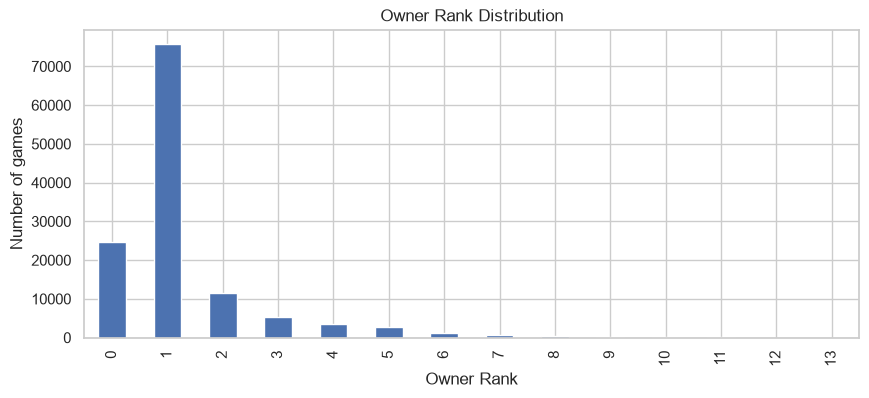

In [28]:
df['Owner Rank'].value_counts().sort_index().plot(kind='bar', figsize=(10, 4),
                                                   title='Owner Rank Distribution')
plt.xlabel('Owner Rank')
plt.ylabel('Number of games')
plt.show()

### Filtering games with too few reviews

A review score based on a handful of reviews is unreliable. A game with 3 positive and 0 negative reviews shows 100%. A new column, **Total reviews** = Positive + Negative, is used to filter these games out.

Two thresholds were compared:

In [29]:
df['Total reviews'] = df['Positive'] + df['Negative']

comparison = pd.DataFrame({
    t: {'Rows kept': (df['Total reviews'] >= t).sum(),
        '% removed': round((df['Total reviews'] < t).mean() * 100, 2)}
    for t in [20, 50]
}).T.astype({'Rows kept': 'int64'})
comparison.index.name = 'Min reviews'
comparison

,Rows kept,% removed
Min reviews,,
20,44568,64.59
50,30624,75.67


A threshold of **50** was chosen. It still leaves over 30,000 games, and a score built from 50+ reviews is much more stable than one built from 20.

In [30]:
before = len(df)
df = df[df['Total reviews'] >= 50].copy()

print(f'Rows: {before:,} → {len(df):,}')
print(f'Removed: {100 - len(df) / before * 100:.2f}%')

Rows: 125,855 → 30,624
Removed: 75.67%


In [31]:
df['Owner Rank'].value_counts().sort_index()

Owner Rank
1     11598
2      6671
3      4118
4      3052
5      2711
6      1130
7       720
8       404
9       125
10       51
11       31
12        9
13        4
Name: count, dtype: int64

About **75.7%** of games had fewer than 50 reviews and were removed (125,855 → 30,624 rows). As a side effect, every `0 - 0` (Owner Rank 0) game is gone. These were the dead store entries flagged in Section 3.

> **Note:** `Positive`, `Negative`, `Total reviews` and `Owner Rank` are outcomes. They are only used to build the target and for EDA, and will **not** be used as input features (X).

### Parsing release dates

The Release date column is a string, so date operations cannot be done on it. Section 3 showed that every value follows the `Mon D, YYYY` format (e.g. `Sep 14, 2018`).

In [32]:
df['Release date']= pd.to_datetime(df['Release date'], format='%b %d, %Y', errors='coerce')
df['Release date'].head(10)

1    2016-07-29
6    2025-04-08
11   2019-09-25
12   2019-09-05
13   2023-04-05
17   2014-10-23
21   2021-10-21
26   2018-11-16
27   2017-07-26
30   2022-01-26
Name: Release date, dtype: datetime64[us]

In [33]:
df['Release date'].isnull().sum()

np.int64(0)

In [34]:
df_dates=df.sort_values(by='Release date' ,ascending=True)
df_dates[['Name', 'Release date']].head(10)

,Name,Release date
103735,Carmageddon Max Pack,1997-06-30
76124,POSTAL,1997-11-14
67387,Half-Life,1998-11-19
33479,Team Fortress Classic,1999-04-01
64365,Half-Life: Opposing Force,1999-11-01
59485,Counter-Strike,2000-11-01
12104,Ricochet,2000-11-01
119140,Gothic 1,2001-03-15
77595,Deathmatch Classic,2001-06-01
96359,Half-Life: Blue Shift,2001-06-01


The earliest games are from 1997–2002, before Steam existed. These are correct original release dates of classic games (e.g. *Half-Life*, *Counter-Strike*) that were later sold on Steam, not errors, so they are kept.

In [35]:
df['Month'] = df['Release date'].dt.month
df['Year'] = df['Release date'].dt.year

In [36]:
print(df['Month'].value_counts().sort_index())
print(df['Year'].value_counts().sort_index())

Month
1     2201
2     2403
3     2669
4     2726
5     2795
6     2218
7     2425
8     2590
9     2712
10    2974
11    2578
12    2333
Name: count, dtype: int64
Year
1997       2
1998       1
1999       2
2000       2
2001       4
2002       1
2003       3
2004       6
2005       7
2006      64
2007      87
2008     137
2009     259
2010     213
2011     240
2012     309
2013     433
2014    1367
2015    1902
2016    2566
2017    2688
2018    2716
2019    2426
2020    2751
2021    2571
2022    2438
2023    2697
2024    3215
2025    1517
Name: count, dtype: int64


- The Release date column is now a datetime.
- Month and Year have their own columns.
- 2025 has fewer games than 2024 because the data was collected around December 2025, and many recent games have not reached 50 reviews yet.

### Resolving repeated game names

In [37]:
df[df['Name'].duplicated()]['Name'].value_counts()

Name
Shadow of the Tomb Raider: Definitive Edition    19
Tom Clancy's Rainbow Six® Siege X                 4
Train Simulator Classic                           4
Hide and Seek                                     2
Gear Up                                           2
                                                 ..
Ys I & II Chronicles+                             1
Northern Lights                                   1
Dark Days                                         1
DEFECTIVE                                         1
Tropico Reloaded                                  1
Name: count, Length: 85, dtype: int64

In [38]:
df[df['Name']=="Tom Clancy's Rainbow Six® Siege X"]

,AppID,Name,Release date,Estimated owners,Price,Supported languages,Full audio languages,Windows,Mac,Linux,Positive,Negative,Developers,Publishers,Categories,Genres,Tags,Owner Rank,Total reviews,Month,Year
9187,488821,Tom Clancy's Rainbow Six® Siege X,2015-12-01,0 - 20000,0.0,"['English', 'French', 'Italian', 'German', 'Sp...","['English', 'French', 'Italian', 'German', 'Sp...",True,False,False,312232,64137,Ubisoft Montreal,Ubisoft,"Single-player,Multi-player,PvP,Online PvP,Co-o...","Action,Free To Play","FPS,Multiplayer,Tactical,Shooter,Team-Based,Ac...",1,376369,12,2015
10471,488822,Tom Clancy's Rainbow Six® Siege X,2015-12-01,0 - 20000,0.0,"['English', 'French', 'Italian', 'German', 'Sp...","['English', 'French', 'Italian', 'German', 'Sp...",True,False,False,312397,64151,Ubisoft Montreal,Ubisoft,"Single-player,Multi-player,PvP,Online PvP,Co-o...","Action,Free To Play","FPS,Multiplayer,Tactical,Shooter,Team-Based,Ac...",1,376548,12,2015
38815,488823,Tom Clancy's Rainbow Six® Siege X,2015-12-01,0 - 20000,0.0,"['English', 'French', 'Italian', 'German', 'Sp...","['English', 'French', 'Italian', 'German', 'Sp...",True,False,False,312719,64188,Ubisoft Montreal,Ubisoft,"Single-player,Multi-player,PvP,Online PvP,Co-o...","Action,Free To Play","FPS,Multiplayer,Tactical,Shooter,Team-Based,Ac...",1,376907,12,2015
40969,359550,Tom Clancy's Rainbow Six® Siege X,2015-12-01,20000000 - 50000000,0.0,"['English', 'French', 'Italian', 'German', 'Sp...","['English', 'French', 'Italian', 'German', 'Sp...",True,False,False,1172854,225730,Ubisoft Montreal,Ubisoft,"Single-player,Multi-player,PvP,Online PvP,Co-o...","Action,Free To Play","FPS,PvP,Multiplayer,Tactical,e-sports,Shooter,...",11,1398584,12,2015
78473,488824,Tom Clancy's Rainbow Six® Siege X,2015-12-01,0 - 20000,0.0,"['English', 'French', 'Italian', 'German', 'Sp...","['English', 'French', 'Italian', 'German', 'Sp...",True,False,False,312816,64201,Ubisoft Montreal,Ubisoft,"Single-player,Multi-player,PvP,Online PvP,Co-o...","Action,Free To Play","FPS,Multiplayer,Tactical,Shooter,Team-Based,Ac...",1,377017,12,2015


These repeated names are alternate listings of the same game (editions or regional versions). Games sometimes have to be published separately in certain regions because of regional censorship laws, so they get different AppIDs.

**Decision:** For each group with the same name and developer, keep the listing with the most reviews. Summing the reviews was rejected because it would double-count: the alternate listings together showed about four times the main listing's reviews. Matching on developer keeps different games that share a title separate, and removing the duplicates stops the same game from appearing in both the training and test sets.

In [39]:
df_sorted=df.sort_values(by='Total reviews', ascending=False)
df_sorted.head(5)

,AppID,Name,Release date,Estimated owners,Price,Supported languages,Full audio languages,Windows,Mac,Linux,Positive,Negative,Developers,Publishers,Categories,Genres,Tags,Owner Rank,Total reviews,Month,Year
45509,730,Counter-Strike 2,2012-08-21,100000000 - 200000000,0.00,"['Czech', 'Danish', 'Dutch', 'English', 'Finni...","['English', 'Indonesian']",True,False,True,7642084,1173003,Valve,Valve,"Multi-player,Cross-Platform Multiplayer,Steam ...","Action,Free To Play","FPS,Shooter,Multiplayer,Competitive,Action,Tea...",13,8815087,8,2012
8878,578080,PUBG: BATTLEGROUNDS,2017-12-21,100000000 - 200000000,0.00,"['English', 'Korean', 'Simplified Chinese', 'F...",[],True,False,False,1520457,1037487,PUBG Corporation,"KRAFTON, Inc.","Multi-player,PvP,Online PvP,Stats,Remote Play ...","Action,Adventure,Massively Multiplayer,Free To...","Survival,Shooter,Battle Royale,Multiplayer,FPS...",13,2557944,12,2017
4193,570,Dota 2,2013-07-09,100000000 - 200000000,0.00,"['Bulgarian', 'Czech', 'Danish', 'Dutch', 'Eng...","['English', 'Korean', 'Simplified Chinese', 'V...",True,True,True,2037143,461826,Valve,Valve,"Multi-player,Co-op,Steam Trading Cards,Steam W...","Action,Strategy,Free To Play","Free to Play,MOBA,Multiplayer,Strategy,e-sport...",13,2498969,7,2013
59122,271590,Grand Theft Auto V Legacy,2015-04-13,50000000 - 100000000,0.00,"['English', 'French', 'Italian', 'German', 'Sp...","['English', 'Spanish - Latin America']",True,False,False,1739980,250576,Rockstar North,Rockstar Games,"Single-player,Multi-player,PvP,Online PvP,Co-o...","Action,Adventure","Open World,Action,Multiplayer,Crime,Automobile...",12,1990556,4,2015
10927,105600,Terraria,2011-05-16,20000000 - 50000000,4.99,"['English', 'French', 'Italian', 'German', 'Sp...",[],True,True,True,1373979,35494,Re-Logic,Re-Logic,"Single-player,Multi-player,PvP,Online PvP,Co-o...","Action,Adventure,Indie,RPG","Open World Survival Craft,Sandbox,Survival,2D,...",11,1409473,5,2011


In [40]:
df_sorted.drop_duplicates(subset=['Name','Developers'], keep='first', inplace=True)

In [41]:
df_sorted[df_sorted['Name']=="Tom Clancy's Rainbow Six® Siege X"]

,AppID,Name,Release date,Estimated owners,Price,Supported languages,Full audio languages,Windows,Mac,Linux,Positive,Negative,Developers,Publishers,Categories,Genres,Tags,Owner Rank,Total reviews,Month,Year
40969,359550,Tom Clancy's Rainbow Six® Siege X,2015-12-01,20000000 - 50000000,0.0,"['English', 'French', 'Italian', 'German', 'Sp...","['English', 'French', 'Italian', 'German', 'Sp...",True,False,False,1172854,225730,Ubisoft Montreal,Ubisoft,"Single-player,Multi-player,PvP,Online PvP,Co-o...","Action,Free To Play","FPS,PvP,Multiplayer,Tactical,e-sports,Shooter,...",11,1398584,12,2015


In [42]:
print(len(df))
print(len(df_sorted))
print('Repeated name + developer:', df_sorted.duplicated(subset=['Name','Developers']).sum())
print('Repeated names only      :', df_sorted['Name'].duplicated().sum())

30624
30542
Repeated name + developer: 0
Repeated names only      : 32


In [43]:
df_sorted[df_sorted[ 'Name'].duplicated()][ 'Name'].value_counts(ascending=False)

Name
Hide and Seek             2
Ys X: Nordics             1
Flashback                 1
Lighthouse Keeper         1
RUSH                      1
Outpost                   1
The Guest                 1
The Good Life             1
Nothing                   1
Out of Sight              1
The Gap                   1
Survivor                  1
First Snow                1
A Walk in the Woods       1
Locked Up                 1
The Hotel                 1
The Deer                  1
Hatch                     1
Instinct                  1
Achievement Clicker       1
Dig Deep                  1
STAY                      1
Graveyard Shift           1
Hell Shooter              1
Northern Lights           1
New York Bus Simulator    1
The Cleaner               1
The Backrooms             1
Streamline                1
DEFECTIVE                 1
Dark Days                 1
Name: count, dtype: int64

In [44]:
df_sorted[df_sorted['Name']=='Hide and Seek']

,AppID,Name,Release date,Estimated owners,Price,Supported languages,Full audio languages,Windows,Mac,Linux,Positive,Negative,Developers,Publishers,Categories,Genres,Tags,Owner Rank,Total reviews,Month,Year
4014,1010860,Hide and Seek,2019-02-01,50000 - 100000,0.54,"['English', 'Russian', 'French', 'Italian', 'G...",[],True,False,False,469,294,Funny Games,Funny Games,"Single-player,Multi-player,PvP,Online PvP,LAN ...","Action,Casual,Indie,Massively Multiplayer,RPG","Casual,Action,Indie,Massively Multiplayer,Mult...",3,763,2,2019
6217,596940,Hide and Seek,2017-08-31,100000 - 200000,0.00,['English'],['English'],True,False,False,149,231,Llama Software,Llama Software,"Multi-player,PvP,Online PvP,Co-op,Online Co-op","Casual,Free To Play,Indie","Free to Play,Multiplayer,Horror,Indie,Casual,S...",4,380,8,2017
34967,1526180,Hide and Seek,2021-11-12,0 - 20000,1.64,"['English', 'French', 'German', 'Simplified Ch...",[],True,False,False,96,32,Lucky Dog,Lucky Dog,"Multi-player,PvP,LAN PvP,Co-op,LAN Co-op,Steam...","Adventure,Indie,Massively Multiplayer,RPG","Indie,Multiplayer,Adventure,Horror,Online Co-O...",1,128,11,2021


No name + developer pair repeats any more. The names that still repeat belong to different games: for example, the three *Hide and Seek* games have different developers, release dates and prices, so all three are kept.

In [45]:
df=df_sorted

### Dropping the Windows column

The Windows column is True for over 99% of games, so it is safe to assume all games run on Windows. The column gives no information.

In [46]:
df['Windows'].value_counts()

Windows
True     30539
False        3
Name: count, dtype: int64

In [47]:
df=df.drop('Windows', axis=1)
print(df.shape)

(30542, 20)


### Parsing language lists

In [48]:
df['Supported languages'].value_counts(normalize=True,ascending=False).head(10)*100

Supported languages
['English']                                                      33.321328
['English', 'Russian']                                            2.553860
['Simplified Chinese']                                            1.899024
['English', 'Japanese']                                           1.587977
['English', 'Simplified Chinese']                                 1.460284
['English', 'French', 'Italian', 'German', 'Spanish - Spain']     1.165608
['English', 'Japanese', 'Simplified Chinese']                     0.775981
['English', 'German']                                             0.772706
['Simplified Chinese', 'English']                                 0.700674
['English', 'Simplified Chinese', 'Traditional Chinese']          0.605723
Name: proportion, dtype: float64

In [49]:
line=df.iloc[0,5]
print(type(line))
print(line)

<class 'str'>
['Czech', 'Danish', 'Dutch', 'English', 'Finnish', 'French', 'German', 'Hungarian', 'Italian', 'Japanese', 'Korean', 'Norwegian', 'Polish', 'Portuguese - Portugal', 'Portuguese - Brazil', 'Romanian', 'Russian', 'Simplified Chinese', 'Spanish - Spain', 'Swedish', 'Thai', 'Traditional Chinese', 'Turkish', 'Bulgarian', 'Ukrainian', 'Greek', 'Spanish - Latin America', 'Vietnamese', 'Indonesian']


In [50]:
print((df['Supported languages']=='[]').sum())

18


After the review filter, 18 games still list no supported languages. Every released game supports at least one language, so `'[]'` here means the data is missing. They are set to NaN first.

In [51]:
df['Supported languages']=df['Supported languages'].replace('[]',np.nan)
print((df['Supported languages']=='[]').sum())

0


In [52]:
df[df['Supported languages'].isnull()]

,AppID,Name,Release date,Estimated owners,Price,Supported languages,Full audio languages,Mac,Linux,Positive,Negative,Developers,Publishers,Categories,Genres,Tags,Owner Rank,Total reviews,Month,Year
17197,803800,WIDECROSS,2019-11-26,20000 - 50000,6.99,NaN,[],False,False,98,83,DEV TEAM,DEV TEAM,"Single-player,Multi-player,PvP,Online PvP,Co-o...","Action,Casual,Indie,Massively Multiplayer,Stra...","Strategy,Action,Massively Multiplayer,Casual,I...",2,181,11,2019
95826,2992180,Apocalypse Delivery Service,2024-06-18,0 - 20000,0.00,NaN,[],False,False,140,8,Teamey,Teamey,Single-player,"Indie,Free To Play","Walking Simulator,Indie,Arcade,Post-apocalypti...",1,148,6,2024
53527,2992200,Airport Antiterror,2024-06-15,0 - 20000,0.00,NaN,[],False,False,120,17,Teamey,Teamey,Single-player,"Action,Casual,Indie,Free To Play","Casual,Action,Arena Shooter,Shooter,Indie,3D,A...",1,137,6,2024
13416,3027160,Lost Girl Platformer,2024-06-15,0 - 20000,0.00,NaN,[],False,False,125,2,Teamey,Teamey,Single-player,"Action,Adventure,Casual,Indie,Free To Play","Side Scroller,Casual,Precision Platformer,Acti...",1,127,6,2024
60104,3034400,Medieval Businessman,2024-06-20,0 - 20000,0.00,NaN,[],False,False,125,2,Teamey,Teamey,Single-player,"Indie,Free To Play","Real Time Tactics,City Builder,Indie,Top-Down,...",1,127,6,2024
113894,2991740,Z Rush,2024-06-18,0 - 20000,0.00,NaN,[],False,False,125,0,Teamey,Teamey,Single-player,"Indie,Free To Play","Hack and Slash,Indie,RTS,3D,Strategy,Zombies,S...",1,125,6,2024
60136,2992230,Greedy Goose,2024-06-06,0 - 20000,0.00,NaN,[],False,False,111,10,Teamey,Teamey,Single-player,"Indie,Free To Play","2D Platformer,Indie,Arcade,Character Action Ga...",1,121,6,2024
1292,2991730,Insert Item Apocalypse,2024-06-18,0 - 20000,0.00,NaN,[],False,False,110,10,Teamey,Teamey,Single-player,"Indie,Free To Play","Hidden Object,Arcade,Indie,Strategy,3D,Post-ap...",1,120,6,2024
62657,3027170,Oil and Sand,2024-06-21,0 - 20000,0.00,NaN,[],False,False,107,8,Teamey,Teamey,Single-player,"Indie,Free To Play","Bullet Hell,Tower Defense,Indie,Arcade,3D,Cold...",1,115,6,2024
92962,3034390,Apocalypse Secrets,2024-06-20,0 - 20000,0.00,NaN,[],False,False,101,1,Teamey,Teamey,Single-player,"Indie,Free To Play","Hidden Object,Indie,Arcade,3D,Post-apocalyptic...",1,102,6,2024


In [53]:
print((df['Full audio languages']=='[]').sum())

15375


About 15,000 games have an empty full-audio list. As shown in Section 3, this means no voice-over, so these are **not** missing and will become a count of 0.

The strings are converted into real Python lists with `ast.literal_eval`. Testing it on one value first:

In [54]:
languages = ast.literal_eval(line)
print(type(languages))
print(len(languages))

<class 'list'>
29


Before parsing the whole column, the malformed *K'iche'* value (Section 3) is fixed. It is renamed to `'Kiche'` with quotes, so Python can read it as a list item.

In [55]:
df['Supported languages']=df['Supported languages'].str.replace("K'iche'","'Kiche'",regex=False)
df['Full audio languages']=df['Full audio languages'].str.replace("K'iche'","'Kiche'",regex=False)

In [56]:
def parse_languages(lang_str):  # will convert the string representation of a list into a list, or return NaN if the input is not a string
    if type(lang_str) == str:
        return ast.literal_eval(lang_str)
    else:
        return np.nan

def is_english(lang_str):
    lang_list = parse_languages(lang_str)
    # will check if 'English' is in the list of languages, or return NaN if the input is not a list
    if type(lang_list) != list:
        return np.nan
    if 'English' in lang_list :
        return 1
    else:
        return 0

def len_languages(lang_str):
    lang_list = parse_languages(lang_str)
    # will return the number of languages in the list, or return NaN if the input is not a list
    if type(lang_list) != list:
        return np.nan
    return len(lang_list)

df['Supports english'] = df['Supported languages'].apply(is_english)

df['Supported languages'] = df['Supported languages'].apply(len_languages)

In [57]:
df['Supported languages'].value_counts()

Supported languages
1.0      10971
2.0       3258
3.0       1840
5.0       1624
4.0       1417
6.0       1367
9.0       1299
8.0       1193
7.0       1186
10.0      1169
11.0      1109
12.0       909
13.0       735
14.0       562
15.0       336
16.0       223
29.0       205
17.0       159
103.0      139
27.0       134
18.0       134
19.0        87
20.0        66
21.0        61
22.0        51
26.0        49
30.0        46
28.0        39
25.0        39
23.0        37
24.0        31
31.0        14
102.0        8
32.0         7
35.0         5
34.0         4
36.0         2
74.0         1
68.0         1
39.0         1
43.0         1
71.0         1
41.0         1
33.0         1
40.0         1
53.0         1
Name: count, dtype: int64

The 18 games with missing languages (0.06% of the data) are dropped. Imputing them would add little for so few rows, and dropping them lets the language count and English flag be stored as integers.

In [58]:
df=df.dropna(subset=['Supported languages'])
df['Supported languages']=df['Supported languages'].astype(int)
df['Supports english']=df['Supports english'].astype(int)
print(df['Supported languages'].isnull().sum())

0


In [59]:
df['Full audio languages'] = df['Full audio languages'].apply(len_languages)
df['Full audio languages'].value_counts()

Full audio languages
0      15357
2       5971
1       5861
3       1114
4        357
6        293
5        273
7        210
8        160
9        152
10       134
103      114
11        81
29        77
12        67
13        62
14        52
27        41
15        31
16        23
17        17
19        12
30        11
20         9
18         9
26         7
28         7
21         5
22         4
31         3
23         3
36         1
24         1
74         1
35         1
68         1
25         1
40         1
Name: count, dtype: int64

The Full audio languages column is now a count of languages. 0 means the game has no voice-over. Over 15,000 games having no voice-over is believable, since not every game has the resources for it.

In [60]:
df[df['Full audio languages']>df['Supported languages']].shape[0]

0

**Check:** no game has more full-audio languages than supported languages, so the two columns are consistent.

Both columns now hold counts, not lists, so they are renamed to say so:

In [61]:
df = df.rename(columns={'Supported languages': 'Language count', 'Full audio languages': 'Full audio count'})
df[['Language count', 'Full audio count', 'Supports english']].head()

,Language count,Full audio count,Supports english
45509,29,2,1
8878,17,0,1
4193,28,4,1
59122,13,2,1
10927,9,0,1


### Dropping tags

**Decision:** Tags are dropped because players vote on them **after** the game is released, which does not align with our pre-release features. Some tags are even quality judgments ("Great Soundtrack", "Masterpiece"), so they partly reflect the target.

In [62]:
df=df.drop('Tags', axis=1)
print(df.shape)

(30524, 20)


### Splitting genres and categories

In [63]:
print(type(df.iloc[0,13]))
df.iloc[0,13].split(',')

<class 'str'>


['Multi-player',
 'Cross-Platform Multiplayer',
 'Steam Trading Cards',
 'Steam Workshop',
 'In-App Purchases',
 'Adjustable Text Size',
 'Camera Comfort',
 'Color Alternatives',
 'Custom Volume Controls',
 'Playable without Timed Input',
 'Stereo Sound',
 'Surround Sound',
 'Valve Anti-Cheat enabled',
 'Stats',
 'Remote Play on Phone',
 'Remote Play on Tablet',
 'Remote Play on TV',
 'Steam Timeline']

In [64]:
# Split the 'Genres' column into a list of genres
df['Genres'] = df['Genres'].str.split(',')
df['Genres'].explode().value_counts()

Genres
Indie                    21044
Adventure                13157
Action                   12791
Casual                   10247
Simulation                7335
RPG                       6832
Strategy                  6661
Free To Play              2652
Early Access              2224
Sports                    1319
Racing                    1059
Massively Multiplayer      941
Utilities                  247
Design & Illustration      162
Animation & Modeling       136
Violent                    125
Gore                        85
Video Production            81
Game Development            75
Education                   67
Audio Production            62
Software Training           51
Web Publishing              46
Sexual Content              40
Photo Editing               38
Nudity                      37
Accounting                   3
Movie                        1
Name: count, dtype: int64

In [65]:
# Split the 'Categories' column into a list of categories
df['Categories'] = df['Categories'].str.split(',')
df['Categories'].explode().value_counts()

Categories
Single-player                   28839
Family Sharing                  26425
Steam Achievements              20113
Steam Cloud                     13377
Full controller support          9582
Steam Trading Cards              9228
Multi-player                     7682
Partial Controller Support       4692
Co-op                            4357
PvP                              4190
Online PvP                       3438
Steam Leaderboards               3387
Online Co-op                     2866
Remote Play Together             2843
Shared/Split Screen              2464
Stats                            1853
Remote Play on TV                1724
Steam Workshop                   1687
Shared/Split Screen PvP          1557
Shared/Split Screen Co-op        1491
Cross-Platform Multiplayer       1453
Tracked Controller Support       1284
Custom Volume Controls           1267
Includes level editor            1244
In-App Purchases                 1154
Playable without Timed Input     1088
V

### Missing genres and categories

In [66]:
df[['Genres','Categories']].isnull().sum()

Genres         81
Categories    164
dtype: int64

In [67]:
df[df['Categories'].isnull()][['Name', 'Genres', 'Total reviews']].head(10)

,Name,Genres,Total reviews
50463,Blender,"[Animation & Modeling, Design & Illustration, ...",72881
115493,Lossless Scaling,[Utilities],24888
85251,Aseprite,"[Animation & Modeling, Design & Illustration, ...",21818
51883,Might & Magic: Heroes VI,"[RPG, Strategy]",8890
119021,小黑盒加速器,"[Software Training, Web Publishing, Game Devel...",8888
74671,ShareX,"[Free To Play, Audio Production, Design & Illu...",7524
106929,Action! - Gameplay Recording and Streaming,"[Audio Production, Education, Software Trainin...",7251
84773,VRoid Studio v2.7.0,"[Free To Play, Animation & Modeling, Design & ...",4232
30076,VEGAS Pro 18 Edit Steam Edition,"[Audio Production, Video Production]",2337
95699,Fuse,"[Animation & Modeling, Design & Illustration, ...",2240


The games missing `Categories` are mostly software, not games (e.g. Blender, Aseprite, ShareX), because software doesn't list Steam game features like single-player or achievements. The missingness is explained by another column, `Genres`, so it is **Missing At Random (MAR)**. Games missing `Genres` are mostly real games.

Together, these rows are under 1% of the data, so they are dropped.

In [68]:
print(len(df))
df=df.dropna(subset=['Genres','Categories'])
print(len(df))

30524
30280


### Removing non-game listings

Some entries are software, not games: genres such as Utilities, Design & Illustration, Video Production and Audio Production appear. Some real games also carry one of these labels (e.g. "Action, Education"), so a listing is only treated as a non-game if it has **no game genre at all**. Free To Play and Early Access are not counted as game genres, because software can be free or in early access too.

In [69]:
games_set={'Indie','Adventure','Action','Casual','RPG','Simulation','Strategy','Sports','Racing','Massively Multiplayer'}
#games have at least one of the above genres

def is_game(genre_list):
    for i in genre_list:
        if i in games_set:
            return 1
    return 0

df['game_mask']=df['Genres'].apply(is_game)
df['game_mask'].value_counts()

game_mask
1    30061
0      219
Name: count, dtype: int64

In [70]:
df[df['game_mask']==0][['Name', 'Genres']].sample(5, random_state=42)

,Name,Genres
61763,Bot Maker For Discord,"[Utilities, Web Publishing]"
89096,SMILE GAME BUILDER,"[Design & Illustration, Web Publishing, Game D..."
40660,AutoDepth Image Viewer,"[Photo Editing, Utilities]"
71808,3DMark 11,[Utilities]
83366,OVR Toolkit - Desktop Overlay,[Utilities]


In [71]:
print("Num of rows before filtering:", len(df))

df=df[df['game_mask']==1]

print("Num of rows after filtering:", len(df))

Num of rows before filtering: 30280
Num of rows after filtering: 30061


### Creating genre flags

A list column can't be used by a model or saved cleanly to CSV. Each game genre, plus Free To Play and Early Access, becomes a 0/1 column. The list of genres is fixed, so this doesn't learn anything from the data and is safe to do before the train/test split.

In [72]:
genre_list = ['Indie', 'Adventure', 'Action', 'Casual', 'Simulation', 'RPG', 'Strategy',
              'Sports', 'Racing', 'Massively Multiplayer', 'Free To Play', 'Early Access']

def has_genre(game_genres, genre):
    # 1 if the game has this genre, otherwise 0
    if genre in game_genres:
        return 1
    else:
        return 0

for genre in genre_list:
    df['Genre: ' + genre] = df['Genres'].apply(has_genre, genre=genre)

df.filter(like='Genre: ').sum()

Genre: Indie                    21040
Genre: Adventure                13157
Genre: Action                   12791
Genre: Casual                   10244
Genre: Simulation                7330
Genre: RPG                       6829
Genre: Strategy                  6660
Genre: Sports                    1319
Genre: Racing                    1058
Genre: Massively Multiplayer      941
Genre: Free To Play              2605
Genre: Early Access              2166
dtype: int64

### Grouping categories

In [73]:
categories=df['Categories'].explode()
categories.value_counts()

Categories
Single-player                   28710
Family Sharing                  26335
Steam Achievements              20022
Steam Cloud                     13304
Full controller support          9550
Steam Trading Cards              9199
Multi-player                     7658
Partial Controller Support       4659
Co-op                            4344
PvP                              4174
Online PvP                       3423
Steam Leaderboards               3375
Online Co-op                     2857
Remote Play Together             2835
Shared/Split Screen              2459
Stats                            1843
Remote Play on TV                1721
Steam Workshop                   1643
Shared/Split Screen PvP          1553
Shared/Split Screen Co-op        1487
Cross-Platform Multiplayer       1451
Custom Volume Controls           1265
Tracked Controller Support       1222
Includes level editor            1213
In-App Purchases                 1137
Playable without Timed Input     1084
V

There are 58 categories, most of them rare and many overlapping (e.g. "Co-op", "Online Co-op", "Shared/Split Screen Co-op"). They are combined into 10 binary (0/1) features, each meaning "has at least one of these categories": Single-player, Online multiplayer, Local multiplayer, Co-op, Controller support, VR, Steam features, Modding, In-App Purchases, Remote Play on devices.

This also merges the duplicate labels from Section 3 ("VR Support" / "VR Supported" into VR, and the two "Mods" labels into Modding).

Left out on purpose:
- **Steam Trading Cards:** Valve only grants trading cards once a game reaches a certain level of sales, so it reflects success after release.
- **Family Sharing:** enabled by default for almost all games, so it reflects Steam policy rather than a developer decision.
- **Accessibility options** (Captions, Subtitle Options, ...): Steam added these labels recently, so "not listed" mostly means "not updated", not "absent".

In [74]:
# Each new feature = 1 if the game has at least one category from its group
category_groups = {
    'Single-player': {'Single-player'},
    'Online multiplayer': {'Multi-player', 'PvP', 'Online PvP', 'Online Co-op',
                           'MMO', 'Cross-Platform Multiplayer'},
    'Local multiplayer': {'Shared/Split Screen', 'Shared/Split Screen PvP',
                          'Shared/Split Screen Co-op', 'LAN Co-op', 'LAN PvP',
                          'Remote Play Together'},
    'Co-op': {'Co-op', 'Online Co-op', 'Shared/Split Screen Co-op', 'LAN Co-op'},
    'Controller support': {'Full controller support', 'Partial Controller Support'},
    'VR': {'VR Only', 'VR Supported', 'VR Support', 'Tracked Controller Support',
           'SteamVR Collectibles'},
    'Steam features': {'Steam Achievements', 'Steam Cloud', 'Steam Leaderboards', 'Stats'},
    'Modding': {'Steam Workshop', 'Includes level editor', 'Includes Source SDK',
                'Mods', 'Mods (require HL2)'},
    'In-App Purchases': {'In-App Purchases'},
    'Remote Play on devices': {'Remote Play on TV', 'Remote Play on Tablet',
                               'Remote Play on Phone'},
}

# Turn each game's list of categories into a set
category_sets = df['Categories'].apply(set)

def has_any(game_categories, group):
    # True if the two sets share at least one category
    return int(not game_categories.isdisjoint(group))

for feature, group in category_groups.items():
    df['Cat: ' + feature] = category_sets.apply(has_any, group=group)

In [75]:
df.filter(like='Cat: ').sum()

Cat: Single-player             28710
Cat: Online multiplayer         7689
Cat: Local multiplayer          3449
Cat: Co-op                      4356
Cat: Controller support        14203
Cat: VR                         1471
Cat: Steam features            21970
Cat: Modding                    2117
Cat: In-App Purchases           1137
Cat: Remote Play on devices     2107
dtype: int64

### Separating free-to-play games from unknown prices

Genuinely free-to-play games have a price of 0.0, but some paid games that are delisted, or replaced by a newer edition, also have a price of 0.0.

In [76]:
#count of games with price 0.0:
print(df[df['Price']== 0.0]['AppID'].count())

#count of games with price 0.0 and 'Free To Play' in Genres:
def is_free_to_play(genre_list):
    if 'Free To Play' in genre_list:
        return 1
    else:
        return 0
print(df[(df['Price']== 0.0) & (df['Genres'].apply(is_free_to_play)==1)]['AppID'].count())

3882
2566


In [77]:
df[(df['Price']== 0.0) & (df['Genres'].apply(is_free_to_play)==0)][['Name', 'Price', 'Total reviews', 'Genres']].head(10)

,Name,Price,Total reviews,Genres
59122,Grand Theft Auto V Legacy,0.0,1990556,"[Action, Adventure]"
27431,Call of Duty®,0.0,714114,[Action]
17066,Rocket League®,0.0,583220,"[Action, Indie, Racing, Sports]"
4117,Fall Guys,0.0,473743,"[Action, Casual, Indie, Massively Multiplayer,..."
82773,Life is Strange - Episode 1,0.0,169201,"[Action, Adventure]"
118904,EA SPORTS™ FIFA 23,0.0,151419,"[Simulation, Sports]"
33095,Horizon Zero Dawn™ Complete Edition,0.0,125197,"[Action, Adventure, RPG]"
44115,FIFA 22,0.0,120871,"[Simulation, Sports]"
69249,EA SPORTS FC™ 24,0.0,109574,"[Simulation, Sports]"
70280,Poppy Playtime,0.0,98914,"[Action, Adventure, Indie]"


The price-0 games without the "Free To Play" genre are a mix of two groups:
- **Paid games no longer on sale.** *Grand Theft Auto V Legacy* was replaced by the Enhanced version, so it is no longer sold separately; older FIFA editions were delisted.
- **Genuinely free games without the tag**, such as *Rocket League* and *Fall Guys*, which became free-to-play later.

No column can tell the two apart, so their price is treated as **unknown**: a `Price unknown` flag is added and the price is set to NaN. The missing prices are imputed after the train/test split, using the training data only.

In [78]:
def free_mask(row):
    if row['Price']== 0.0 and is_free_to_play(row['Genres'])==0:
        return 1
    else:
        return 0

df['Price unknown'] = df.apply(free_mask, axis=1)

In [79]:
#setting the price to nan where price is unknown (0.0 and not Free To Play)
df.loc[df['Price unknown']==1,'Price']=np.nan

In [80]:
print(df['Price unknown'].sum())
print(df['Price'].isna().sum())
print((df['Price']==0).sum())

1316
1316
2566


### Missing developers and publishers

In [81]:
df[['Developers', 'Publishers']].isnull().sum()

Developers      1
Publishers    221
dtype: int64

In [82]:
df[['Developers', 'Publishers']].nunique()

Developers    18693
Publishers    14315
dtype: int64

In [83]:
df[df['Publishers'].isnull()][['Name', 'Developers', 'Publishers']].head(10)

,Name,Developers,Publishers
4117,Fall Guys,Mediatonic,NaN
21846,Super Meat Boy,Team Meat,NaN
75183,Marauders,Small Impact Games,NaN
49337,Operation: Harsh Doorstop,Drakeling Labs,NaN
2165,Drunken Wrestlers 2,Oleg Skutte,NaN
14803,Hired Ops,Absolut Soft LLC,NaN
54803,Cat Goes Fishing,Cat5Games,NaN
45018,S.K.I.L.L. - Special Force 2 (Shooter),"Dragonfly GF Co., LTD",NaN
29028,AudioSurf,Dylan Fitterer,NaN
102595,Poker Night at the Inventory,Telltale Games,NaN


Publishers for 221 games are missing because most are indie games that are self-published, and Steam often leaves the publisher blank in that case.

The exception is *Fall Guys*: it was originally published by Devolver Digital, and its publisher changed after Epic Games acquired its developer, Mediatonic, which likely left the field empty.

**Decision:**
- Drop the single game with no developer.
- Fill the missing publishers with the developer. This uses only the same row, not values from other games, so it is a rule-based correction rather than statistical imputation. For *Fall Guys* it gives Mediatonic, which is reasonable since Epic owns Mediatonic.

In [84]:
#dropping single game with no developer
df = df.dropna(subset=['Developers'])

df['Publishers'] = df['Publishers'].fillna(df['Developers'])
print(df[['Developers', 'Publishers']].isnull().sum())

Developers    0
Publishers    0
dtype: int64


In [85]:
df[df['Name']=='Fall Guys'][['Name', 'Developers', 'Publishers']]

,Name,Developers,Publishers
4117,Fall Guys,Mediatonic,Mediatonic


### Converting platform columns

`Mac` and `Linux` are True/False. They are converted to 0/1 like the other flag columns.

In [86]:
df['Mac']=df['Mac'].astype(int)
df['Linux']=df['Linux'].astype(int)
df[['Mac','Linux']].sum()

Mac      8404
Linux    5578
dtype: int64

### Creating the target

The target is the share of positive reviews: `Review score` = Positive / (Positive + Negative). `Total reviews` already holds the denominator.

In [87]:
df['Review score'] = df['Positive'] / df['Total reviews']
df['Review score'].describe()

count    30060.000000
mean         0.785611
std          0.154595
min          0.071429
25%          0.701158
50%          0.820896
75%          0.905111
max          1.000000
Name: Review score, dtype: float64

### Outliers remaining after cleaning

The review filter removed the joke listings priced in the hundreds of dollars, since they had almost no reviews. Checking what is left:

count    28744.000000
mean         5.690317
std          7.107611
min          0.000000
25%          1.190000
50%          3.740000
75%          7.990000
max        199.990000
Name: Price, dtype: float64

Skewness: 5.93
Games priced above $100: 5


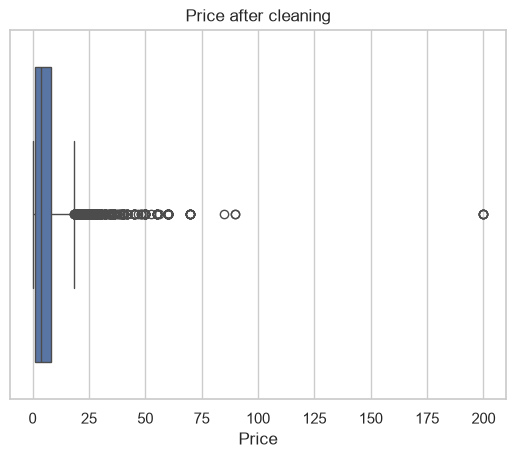

In [88]:
print(df['Price'].describe())
print('\nSkewness:', round(df['Price'].skew(), 2))
print('Games priced above $100:', (df['Price'] > 100).sum())

sns.boxplot(x=df['Price'])
plt.title('Price after cleaning')
plt.show()

Price is still right-skewed (skew about 5.9, down from 22), but the extreme joke listings are gone: the maximum is now 199.99 USD and only 5 games cost more than 100 USD. The remaining high prices belong to real games with 50+ reviews, so they are kept. The skew is handled in preprocessing after the split (e.g. a log transform), using the training data only.

### Final cleanup

Columns dropped and why:
- `game_mask`: helper column from the non-game filter; every remaining row is 1.
- `AppID`, `Name`: identifiers. They carry no information the model can use to predict a new game's score.
- `Estimated owners`: replaced by `Owner Rank`, which holds the same information as a number.
- `Genres`, `Categories`: replaced by the `Genre:` and `Cat:` flag columns.

In [89]:
df=df.drop(columns=['game_mask','AppID','Name','Estimated owners','Genres','Categories'])
df.info()

<class 'pandas.DataFrame'>
Index: 30060 entries, 45509 to 38578
Data columns (total 39 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   Release date                  30060 non-null  datetime64[us]
 1   Price                         28744 non-null  float64       
 2   Language count                30060 non-null  int64         
 3   Full audio count              30060 non-null  int64         
 4   Mac                           30060 non-null  int64         
 5   Linux                         30060 non-null  int64         
 6   Positive                      30060 non-null  int64         
 7   Negative                      30060 non-null  int64         
 8   Developers                    30060 non-null  str           
 9   Publishers                    30060 non-null  str           
 10  Owner Rank                    30060 non-null  int64         
 11  Total reviews                 30060 non-

### Saving the files

- **Raw dataset:** `steam_games_raw.csv` is the original Kaggle `games.csv`, renamed and never modified. The notebook only reads it, so the raw data stays unchanged.
- **Cleaned dataset:** saved to `steam_games_cleaned.csv`.

In [90]:
df.to_csv('steam_games_cleaned.csv', index=False)
print('Saved:', df.shape)

Saved: (30060, 39)


## Section 5: Exploratory Analysis and Insights

### Target distribution

count    30060.000000
mean         0.785611
std          0.154595
min          0.071429
25%          0.701158
50%          0.820896
75%          0.905111
max          1.000000
Name: Review score, dtype: float64

Skewness: -1.08
Share at 0.80 or above: 55.2 %
Share below 0.50      : 5.9 %


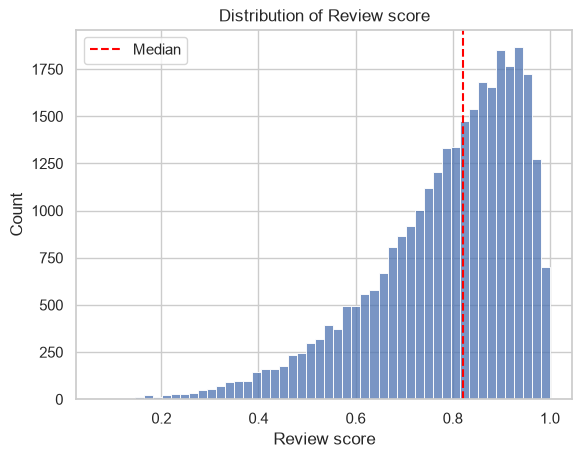

In [91]:
print(df['Review score'].describe())
print('\nSkewness:', round(df['Review score'].skew(), 2))
print('Share at 0.80 or above:', round((df['Review score'] >= 0.8).mean() * 100, 1), '%')
print('Share below 0.50      :', round((df['Review score'] < 0.5).mean() * 100, 1), '%')

sns.histplot(df['Review score'], bins=50)
plt.axvline(df['Review score'].median(), color='red', linestyle='--', label='Median')
plt.title('Distribution of Review score')
plt.legend()
plt.show()

**Insight: the target is skewed towards high scores.** The median game scores **0.82**, and **55.2%** of games score 0.80 or higher, while only **5.9%** score below 0.50 (skewness −1.08). Steam players review positively more often than not, so a "good" score here means something like 0.85+, not 0.5. Because the target is bunched up at the high end, model errors should be judged against this narrow range.

### Numeric features and their relationship with the target

In [92]:
num_cols = ['Review score', 'Price', 'Language count', 'Full audio count', 'Year', 'Month', 'Supports english', 'Mac', 'Linux']
df[num_cols].describe()

,Review score,Price,Language count,Full audio count,Year,Month,Supports english,Mac,Linux
count,30060.000000,28744.000000,30060.000000,30060.000000,30060.000000,30060.000000,30060.000000,30060.000000,30060.000000
mean,0.785611,5.690317,5.848037,1.735163,2019.212275,6.573852,0.965569,0.279574,0.185562
std,0.154595,7.107611,8.807937,6.903783,3.828089,3.400709,0.182337,0.448797,0.388759
min,0.071429,0.000000,1.000000,0.000000,1997.000000,1.000000,0.000000,0.000000,0.000000
25%,0.701158,1.190000,1.000000,0.000000,2017.000000,4.000000,1.000000,0.000000,0.000000
50%,0.820896,3.740000,3.000000,1.000000,2019.000000,7.000000,1.000000,0.000000,0.000000
75%,0.905111,7.990000,9.000000,2.000000,2022.000000,10.000000,1.000000,1.000000,0.000000
max,1.000000,199.990000,103.000000,103.000000,2025.000000,12.000000,1.000000,1.000000,1.000000


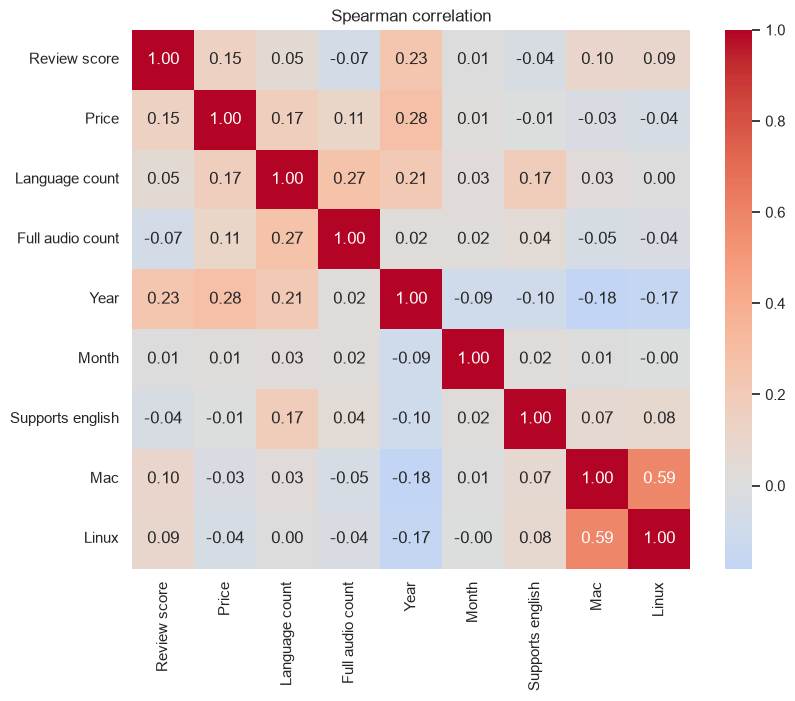

In [93]:
corr = df[num_cols].corr(method='spearman')

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Spearman correlation')
plt.show()

Spearman correlation is used because most of these columns are skewed or ordinal. No single feature is strongly related to the review score on its own: the largest correlations are **Year (0.23)**, **Price (0.15)**, **Mac (0.10)** and **Linux (0.09)**. Release month (0.01) shows essentially no relationship. Mac and Linux are strongly related to each other (0.59), since developers who port to one platform usually port to both.

### Ownership is extremely concentrated

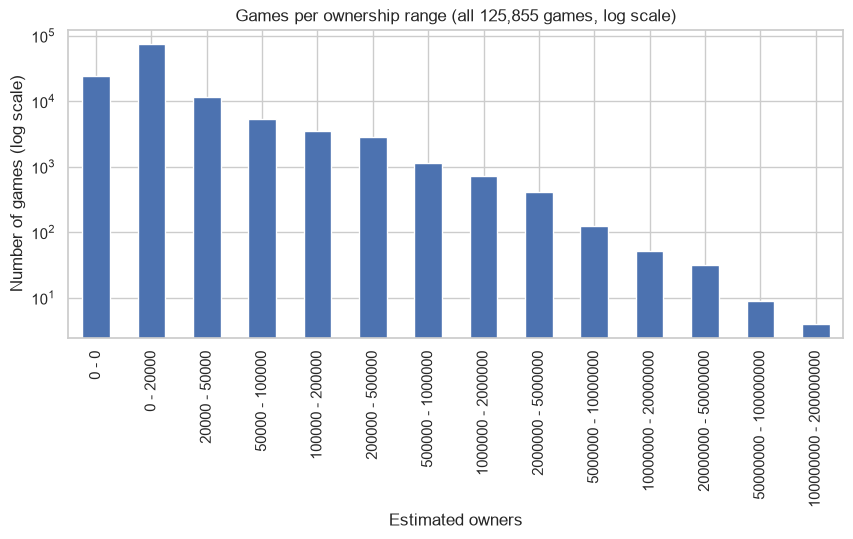

Share in 0 - 20000: 60.2 %
Games with 5M+ owners: 220
Games with 100M+ owners: 4


In [94]:
def upper_bound(owner_range):
    # upper end of an owner range, e.g. '20000 - 50000' -> 50000
    return int(owner_range.split(' - ')[1])

owner_counts = df_raw['Estimated owners'].value_counts()
owner_counts = owner_counts.loc[sorted(owner_counts.index, key=upper_bound)]

owner_counts.plot(kind='bar', figsize=(10, 4), logy=True,
                  title='Games per ownership range (all 125,855 games, log scale)')
plt.ylabel('Number of games (log scale)')
plt.show()

print('Share in 0 - 20000:', round(owner_counts['0 - 20000'] / owner_counts.sum() * 100, 1), '%')
print('Games with 5M+ owners:', owner_counts[[upper_bound(r) > 5000000 for r in owner_counts.index]].sum())
print('Games with 100M+ owners:', owner_counts['100000000 - 200000000'])

**Insight:** Across all 125,855 games, **60.2%** sit in the lowest ownership range (0–20,000 owners), and another 19.5% have no ownership estimate at all. Only **220** games (about 0.2%) reach 5 million owners or more, and just **4** exceed 100 million. Each step up the ladder has far fewer games than the one below, so success on Steam is concentrated in a tiny number of titles.

### Indie games dominate the catalog

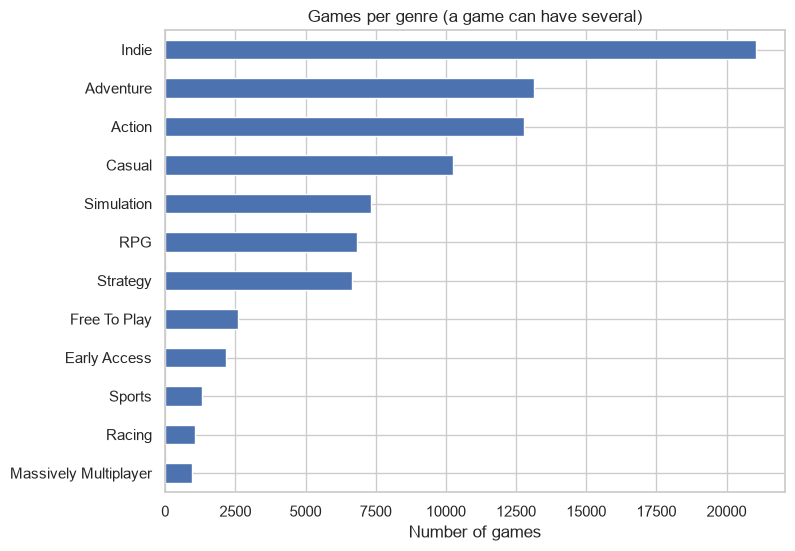

Share of games labelled Indie: 70.0 %


In [95]:
genre_counts = df.filter(like='Genre: ').sum().sort_values()
genre_counts.index = genre_counts.index.str.replace('Genre: ', '')

genre_counts.plot(kind='barh', figsize=(8, 6), title='Games per genre (a game can have several)')
plt.xlabel('Number of games')
plt.show()

print('Share of games labelled Indie:', round(df['Genre: Indie'].mean() * 100, 1), '%')

**Insight:** **70.0%** of games (21,040 of 30,060) are labelled Indie, far more than any other genre. Adventure (13,157) and Action (12,791) follow. Since a game can have several genres, Indie usually appears alongside another genre rather than on its own. With most of the catalog being indie, the Indie flag on its own separates games less than the other genre flags do.

### Price sweet spot between 5 USD and 20 USD

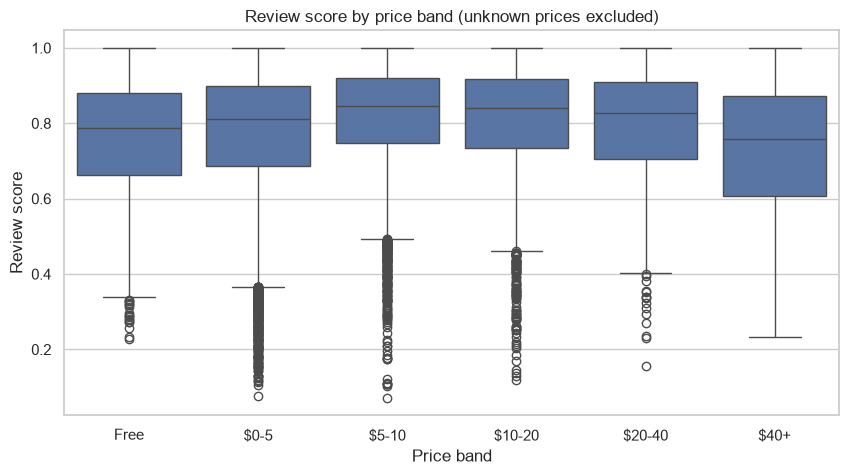

,count,median
Price,,
Free,2565,0.788
$0-5,15981,0.811
$5-10,5842,0.847
$10-20,3576,0.840
$20-40,679,0.827
$40+,101,0.758


In [96]:
price_band = pd.cut(df['Price'], bins=[-0.01, 0, 5, 10, 20, 40, 1000],
                    labels=['Free', '$0-5', '$5-10', '$10-20', '$20-40', '$40+'])

plt.figure(figsize=(10, 5))
sns.boxplot(x=price_band, y=df['Review score'])
plt.title('Review score by price band (unknown prices excluded)')
plt.xlabel('Price band')
plt.show()

df.groupby(price_band, observed=True)['Review score'].agg(['count', 'median']).round(3)

**Insight:** Games priced **5–10 USD** and **10–20 USD** have the highest median scores (**0.847** and **0.840**). Free games (0.788) and games under 5 USD (0.811) score lower, and games above 40 USD score lowest (0.758, though only 101 games). Players seem most satisfied with mid-priced games: cheap and free games attract more casual, critical reviewers, while expensive games face higher expectations. This is a relationship, not proof that changing a game's price would change its score.

### Monetised online games score lower

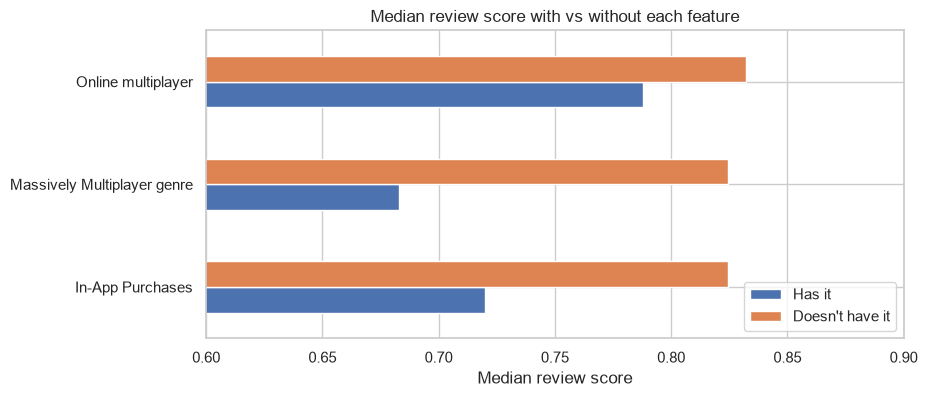

,Has it,Doesn't have it
In-App Purchases,0.720,0.824
Massively Multiplayer genre,0.683,0.824
Online multiplayer,0.788,0.832


In [97]:
monetised = {'In-App Purchases': 'Cat: In-App Purchases',
             'Massively Multiplayer genre': 'Genre: Massively Multiplayer',
             'Online multiplayer': 'Cat: Online multiplayer'}

medians = {}
for name, col in monetised.items():
    medians[name] = {'Has it': df[df[col]==1]['Review score'].median(),
                     "Doesn't have it": df[df[col]==0]['Review score'].median()}
medians = pd.DataFrame(medians).T

medians.plot(kind='barh', figsize=(9, 4), xlim=(0.6, 0.9),
             title='Median review score with vs without each feature')
plt.xlabel('Median review score')
plt.legend(loc='lower right')
plt.show()

medians.round(3)

**Insight:** Games with **in-app purchases** have a median score of **0.720** vs 0.824 without; **Massively Multiplayer** games **0.683** vs 0.824; games with **online multiplayer** 0.788 vs 0.832. Online and monetised games depend on servers, balancing, cheat prevention and the pricing of extras, which are common sources of negative reviews. Of all the features compared, these show the largest gaps in review score.

### Release month doesn't matter

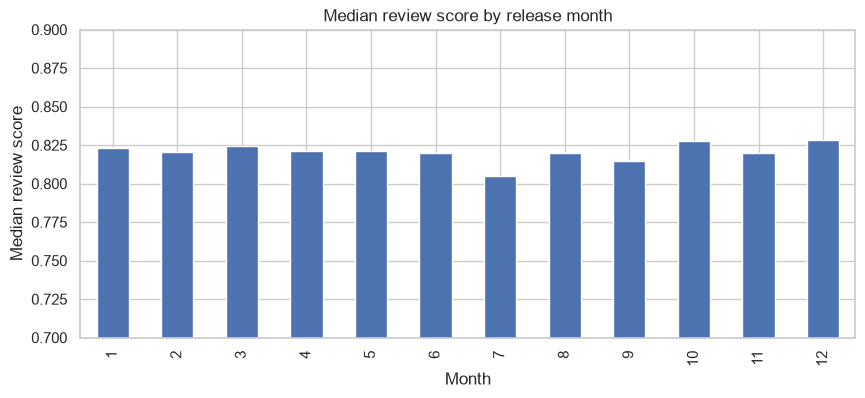

Lowest month median : 0.805
Highest month median: 0.828


In [98]:
month_scores = df.groupby('Month')['Review score'].median()

month_scores.plot(kind='bar', figsize=(10, 4), ylim=(0.7, 0.9),
                  title='Median review score by release month')
plt.ylabel('Median review score')
plt.show()

print('Lowest month median :', round(month_scores.min(), 3))
print('Highest month median:', round(month_scores.max(), 3))

**Insight:** Every month's median score lies between **0.805** (July) and **0.828** (October and December), a spread of only about 0.02, and the Spearman correlation between Month and Review score is **0.01**. Release timing within the year has no visible effect on how well a game is received. For a developer, the release month may matter for visibility and sales, but not for reviews.

### Summary of insights

1. **The review score is skewed high:** median 0.82, and only 5.9% of games score below 0.50.
2. **Ownership is extremely concentrated:** 60.2% of all games have at most 20,000 owners; only 4 exceed 100 million.
3. **Indie games dominate:** 70% of the cleaned catalog is labelled Indie.
4. **Mid-priced games score best:** 5–20 USD games have the highest median scores; free and 40+ USD games the lowest.
5. **Monetised online games score lower:** games with in-app purchases or the Massively Multiplayer genre score about 0.10–0.14 lower than other games.
6. **Release month doesn't matter:** monthly medians differ by only about 0.02.

### Separating features (X) and target (y)

X keeps only pre-release information. These columns are left out:
- `Review score`: the target (y).
- `Positive`, `Negative`, `Total reviews`: used to build y, so they would give the answer away.
- `Owner Rank`: a post-release outcome.
- `Release date`: already represented by `Year` and `Month`.

`Developers` and `Publishers` stay in X; they are encoded after the train/test split, so the encoding is learned from the training data only.

In [99]:
y = df['Review score']
X = df.drop(columns=['Review score', 'Positive', 'Negative', 'Total reviews', 'Owner Rank', 'Release date'])

print('X shape:', X.shape)
print('y shape:', y.shape)
print(X.columns.tolist())

X shape: (30060, 33)
y shape: (30060,)
['Price', 'Language count', 'Full audio count', 'Mac', 'Linux', 'Developers', 'Publishers', 'Month', 'Year', 'Supports english', 'Genre: Indie', 'Genre: Adventure', 'Genre: Action', 'Genre: Casual', 'Genre: Simulation', 'Genre: RPG', 'Genre: Strategy', 'Genre: Sports', 'Genre: Racing', 'Genre: Massively Multiplayer', 'Genre: Free To Play', 'Genre: Early Access', 'Cat: Single-player', 'Cat: Online multiplayer', 'Cat: Local multiplayer', 'Cat: Co-op', 'Cat: Controller support', 'Cat: VR', 'Cat: Steam features', 'Cat: Modding', 'Cat: In-App Purchases', 'Cat: Remote Play on devices', 'Price unknown']


## Section 6: Train-Test Split

### Splitting the data into training and test sets

In [100]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

print('X_train shape: ', X_train.shape)
print('X_test shape: ',X_test.shape)
print('y_train shape: ',y_train.shape)
print('y_test shape: ',y_test.shape)

X_train shape:  (24048, 33)
X_test shape:  (6012, 33)
y_train shape:  (24048,)
y_test shape:  (6012,)


The data is split **80% / 20%** with `random_state=42`, so the split is the same every time the notebook runs.

- **Not stratified:** `stratify` is for classification; the target here is a continuous score.
- **Not time-based:** the data has release dates, but the goal is to understand which pre-release decisions are linked to review scores, not to forecast future releases, so a random split is appropriate.
- **No separate validation set:** this phase doesn't train models. When models are tuned later, cross-validation on the training set will be used, so the test set stays untouched until the final evaluation.

## Section 7: Preprocessing and Feature Selection

Every step that learns something from the data (imputation, encoding, scaling, feature selection) is fitted on the **training set only**, and the fitted transformation is then applied to the test set. This keeps information from the test set out of training.

### Imputing missing prices

In [101]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='median')
X_train[['Price']]=imputer.fit_transform(X_train[['Price']])
X_test[['Price']]=imputer.transform(X_test[['Price']])

imputer.statistics_

array([3.74])

In [102]:
print(X_train['Price'].isna().sum())
print(X_test['Price'].isna().sum())

0
0


`Price` is the only feature with missing values: the 1,316 games whose price was set to unknown in Section 4. They are filled with the **median** price.

**Why the median:** price is right-skewed, so the mean is pulled up by a small number of expensive games. The median represents a typical game better. The `Price unknown` flag keeps the information that these prices were filled in.

**Avoiding leakage:** the imputer is fitted on the training set only (median = 3.74 USD), and the same value is used to fill the test set.

### Handling outliers

Price is strongly right-skewed: most games cost under 10 USD, but a few cost up to 199.99 USD. Price is replaced with `log(1 + Price)` in both sets.

In [103]:
X_train['Price'].skew()

np.float64(6.028426959685271)

In [104]:
X_train['Price'] = np.log1p(X_train['Price'])
X_test['Price'] = np.log1p(X_test['Price'])

X_train['Price'].skew()

np.float64(0.10250101293032278)

**Why a log transform:** it compresses the expensive games instead of removing
them, keeps free games at 0, and doesn't learn anything from the data, so it can
be applied to both sets without leakage. After the transform, the skew drops to
0.10.

In [105]:
X_train[['Language count', 'Full audio count']].skew()

Language count       6.979787
Full audio count    12.479691
dtype: float64

In [106]:
cols=['Language count', 'Full audio count']
for col in cols:
    X_train[col] = np.log1p(X_train[col])
    X_test[col] = np.log1p(X_test[col])
X_train[['Language count', 'Full audio count']].skew()

Language count      0.565401
Full audio count    1.643757
dtype: float64

`Language count` and `Full audio count` are also heavily right-skewed
(training-set skew 6.98 and 12.48): most games support a few languages,
but some list over 100. The same `log(1 + x)` transform is applied, reducing
the skew to 0.57 and 1.64. Full audio count stays somewhat skewed because
about half the games have no voice-over.

### Encoding Month

Month numbers are labels, not quantities: December (12) is not "more" than January (1), and the two are next to each other in time. `Month` is one-hot encoded so each month gets its own 0/1 column.

- `drop='first'` removes January's column: a game with 0 in every other month column must be from January, so that column adds nothing and would make the month columns perfectly dependent on each other in a linear model.
- `handle_unknown='ignore'` gives all zeros instead of an error if the test set ever contains an unseen value.
- The encoder is fitted on the training set and applied to the test set, so both get exactly the same columns.

In [107]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore', drop='first')
encoder.set_output(transform='pandas')

# fit on train, transform test
month_train = encoder.fit_transform(X_train[['Month']])
month_test = encoder.transform(X_test[['Month']])

# replace Month with the new columns
X_train = pd.concat([X_train.drop('Month', axis=1), month_train], axis=1)
X_test = pd.concat([X_test.drop('Month', axis=1), month_test], axis=1)

print(X_train.shape, X_test.shape)
month_train.head()

(24048, 43) (6012, 43)


,Month_2,Month_3,Month_4,Month_5,Month_6,Month_7,Month_8,Month_9,Month_10,Month_11,Month_12
111226,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
59498,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
49698,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
33135,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
70988,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [108]:
#each row has at most one 1 across the month columns (all zeros = January)
print(X_train.filter(like='Month_').sum(axis=1).unique())
print((X_train.columns == X_test.columns).all())

[1. 0.]
True


### Encoding developers and publishers

There are thousands of distinct developers and publishers, far too many to give each one its own column. Each name is replaced with an **experience count**: the number of *other* games by the same developer (or publisher) in the training set.

- An established publisher with hundreds of games gets a high count; a first-time indie developer gets 0.
- For a training game, its own row is not counted (count − 1), so a developer with a single game gets 0.
- For a test game, the count comes from the training set only. A developer that never appears in training gets 0, the same as a first-time developer in training.
- The counts never look at review scores, so there is no target leakage.

Some rows list several companies (e.g. `Volition,KAIKO`); the full string is treated as one name.

In [109]:
dev_counts = X_train['Developers'].value_counts()
pub_counts = X_train['Publishers'].value_counts()

# training set: other games by the same developer / publisher
X_train['Developer experience'] = X_train['Developers'].map(dev_counts) - 1
X_train['Publisher experience'] = X_train['Publishers'].map(pub_counts) - 1

# test set: games by the same developer / publisher in the training set (0 if unseen)
X_test['Developer experience'] = X_test['Developers'].map(dev_counts).fillna(0)
X_test['Publisher experience'] = X_test['Publishers'].map(pub_counts).fillna(0)

X_train = X_train.drop(columns=['Developers', 'Publishers'])
X_test = X_test.drop(columns=['Developers', 'Publishers'])

X_train[['Developer experience', 'Publisher experience']].describe()

,Developer experience,Publisher experience
count,24048.000000,24048.000000
mean,2.702927,12.064454
std,6.730690,23.857243
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,1.000000
75%,2.000000,11.000000
max,73.000000,133.000000


In [110]:
X_train[['Developer experience', 'Publisher experience']].skew()

Developer experience    5.586449
Publisher experience    2.745523
dtype: float64

Both counts are extremely right-skewed: most developers have no other games, while a few publishers have hundreds. The same `log(1 + x)` transform used for price is applied.

In [111]:
cols=['Developer experience', 'Publisher experience']
for col in cols:
    X_train[col] = np.log1p(X_train[col])
    X_test[col] = np.log1p(X_test[col])
X_train[cols].skew()

Developer experience    1.305325
Publisher experience    0.767950
dtype: float64

### Scaling numerical features

The continuous columns are on very different scales: `Year` is around 2019, while the log-transformed counts are between 0 and about 6. Models that use distances or penalties (such as Lasso, used below) would treat the larger numbers as more important, so these columns are standardised to mean 0 and standard deviation 1 with `StandardScaler`.

The 0/1 flag columns (genres, categories, months, platforms, `Supports english`, `Price unknown`) are **not** scaled: they are already on a 0–1 scale, and leaving them as 0/1 keeps them easy to read.

In [112]:
from sklearn.preprocessing import StandardScaler

scale_cols = ['Price', 'Language count', 'Full audio count', 'Year', 'Developer experience', 'Publisher experience']

scaler = StandardScaler()
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test[scale_cols] = scaler.transform(X_test[scale_cols])

X_train[scale_cols].describe().round(2)

,Price,Language count,Full audio count,Year,Developer experience,Publisher experience
count,24048.00,24048.00,24048.00,24048.00,24048.00,24048.00
mean,0.00,0.00,-0.00,0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00
min,-1.74,-1.04,-0.80,-5.81,-0.77,-0.93
25%,-0.81,-1.04,-0.80,-0.58,-0.77,-0.93
50%,0.05,-0.19,0.17,-0.06,-0.77,-0.46
75%,0.72,0.93,0.74,0.73,0.42,0.76
max,4.36,3.80,5.72,1.51,3.91,2.40


After scaling, every continuous column in the training set has a mean of 0 and a standard deviation of 1. The test set uses the training means and standard deviations, so its values are close to, but not exactly, 0 and 1.

### Created features

Several features used here were created during cleaning, each from a single row so there was no leakage:
- `Language count`, `Full audio count`, `Supports english`: from the language lists.
- `Genre:` flags and `Cat:` flags: from the genre and category lists, with categories grouped into 10 meaningful features.
- `Price unknown`: marks games whose price of 0 could not be trusted.
- `Year` and `Month`: from the release date.

In this section, `Developer experience` and `Publisher experience` were added from the training set.

### Feature selection

Three types of feature selection are used, all fitted on the training set only:
- **Filter: mutual information.** Each feature is scored on its own, by how much knowing it reduces uncertainty about the review score. It also catches non-linear relationships.
- **Embedded: Lasso regression.** While fitting, Lasso shrinks the coefficients of unhelpful features to exactly 0; the features left with a non-zero coefficient are selected.
- **Wrapper: recursive feature elimination (RFE).** It repeatedly fits a linear regression, removes the weakest feature, and checks with 5-fold cross-validation how well each number of features performs.

Each method needs a rule for where to stop:
- For the filter, five columns of **pure random noise** are added. A feature is kept only if it scores higher than all of the noise columns; anything lower is no more informative than random numbers.
- For the embedded and wrapper methods, cross-validation always prefers a tiny bit more accuracy, so it tends to keep almost everything. The **one-standard-error rule** is used instead: choose the simplest model whose cross-validated score is within one standard error of the best score. Within that margin, the difference is just noise between folds.

The final features are the ones selected by **all three** methods.

#### Filter method: mutual information

In [113]:
from sklearn.feature_selection import mutual_info_regression

# five columns of random noise as a baseline
rng = np.random.RandomState(42)
X_probe = X_train.copy()
for i in range(1, 6):
    X_probe['Random ' + str(i)] = rng.normal(size=len(X_train))

mi = mutual_info_regression(X_probe, y_train, random_state=42)
mi_scores = pd.Series(mi, index=X_probe.columns).sort_values(ascending=False)

noise_level = mi_scores[mi_scores.index.str.startswith('Random')].max()
print('Highest score of a random column:', round(noise_level, 4))



Highest score of a random column: 0.0108


In [114]:
filter_selected = [name for name in mi_scores.index
                   if not name.startswith('Random') and mi_scores[name] > noise_level]
print('Filter selected', len(filter_selected), 'of', X_train.shape[1], 'features')
print('Not selected:', [c for c in X_train.columns if c not in filter_selected])

Filter selected 10 of 43 features
Not selected: ['Mac', 'Linux', 'Supports english', 'Genre: Indie', 'Genre: Adventure', 'Genre: Action', 'Genre: Casual', 'Genre: Simulation', 'Genre: RPG', 'Genre: Strategy', 'Genre: Sports', 'Genre: Racing', 'Genre: Free To Play', 'Genre: Early Access', 'Cat: Single-player', 'Cat: Local multiplayer', 'Cat: Co-op', 'Cat: VR', 'Cat: Modding', 'Cat: In-App Purchases', 'Cat: Remote Play on devices', 'Price unknown', 'Month_2', 'Month_3', 'Month_4', 'Month_5', 'Month_6', 'Month_7', 'Month_8', 'Month_9', 'Month_10', 'Month_11', 'Month_12']


Features that score no higher than random noise are dropped: only **10 of 43** pass. All 11 month columns are dropped, which matches the insight in Section 5 that release month has no visible effect on review score.

#### Embedded method: Lasso

In [115]:
from sklearn.linear_model import LassoCV, Lasso

lasso_cv = LassoCV(cv=5, random_state=42)
lasso_cv.fit(X_train, y_train)

# one-standard-error rule: the largest alpha whose error is within one standard error of the best
mean_error = lasso_cv.mse_path_.mean(axis=1)
std_error = lasso_cv.mse_path_.std(axis=1) / np.sqrt(5)
best = mean_error.argmin()
alpha_1se = lasso_cv.alphas_[mean_error <= mean_error[best] + std_error[best]].max()

print('Alpha with the lowest error:', lasso_cv.alpha_)
print('Alpha chosen (1-SE rule)   :', alpha_1se)

lasso = Lasso(alpha=alpha_1se)
lasso.fit(X_train, y_train)
lasso_coefs = pd.Series(lasso.coef_, index=X_train.columns)



Alpha with the lowest error: 6.85208148655329e-05
Alpha chosen (1-SE rule)   : 0.0009058048469717068


In [116]:
embedded_selected = lasso_coefs[lasso_coefs != 0].index.tolist()
print('Embedded selected', len(embedded_selected), 'of', X_train.shape[1], 'features')
print('Set to 0:', lasso_coefs[lasso_coefs == 0].index.tolist())

Embedded selected 27 of 43 features
Set to 0: ['Genre: Indie', 'Genre: Sports', 'Genre: Racing', 'Cat: Co-op', 'Cat: VR', 'Price unknown', 'Month_2', 'Month_3', 'Month_4', 'Month_5', 'Month_6', 'Month_7', 'Month_8', 'Month_9', 'Month_10', 'Month_11']


A larger alpha shrinks more coefficients to 0. With the alpha that gives the lowest error, Lasso keeps almost every feature; with the one-standard-error alpha it drops the features whose contribution is too small to matter, at practically no cost in accuracy. The coefficient chart also shows the direction of each effect: for example, `Cat: In-App Purchases` and `Genre: Massively Multiplayer` have negative coefficients, matching the Section 5 insight that monetised online games score lower.

#### Wrapper method: recursive feature elimination

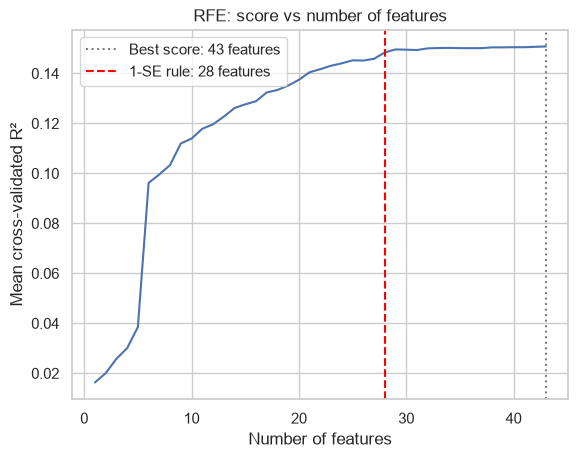

Best R²: 0.1508 with 43 features
R² with 28 features: 0.1484


In [117]:
from sklearn.feature_selection import RFECV, RFE
from sklearn.linear_model import LinearRegression

rfecv = RFECV(LinearRegression(), step=1, cv=5, scoring='r2')
rfecv.fit(X_train, y_train)

mean_score = rfecv.cv_results_['mean_test_score']
std_score = rfecv.cv_results_['std_test_score'] / np.sqrt(5)
best = mean_score.argmax()

# one-standard-error rule: the fewest features whose score is within one standard error of the best
n_features = int(np.argmax(mean_score >= mean_score[best] - std_score[best]) + 1)

plt.plot(range(1, len(mean_score) + 1), mean_score)
plt.axvline(best + 1, color='grey', linestyle=':', label=f'Best score: {best + 1} features')
plt.axvline(n_features, color='red', linestyle='--', label=f'1-SE rule: {n_features} features')
plt.xlabel('Number of features')
plt.ylabel('Mean cross-validated R²')
plt.title('RFE: score vs number of features')
plt.legend()
plt.show()

print('Best R²:', round(mean_score[best], 4), 'with', best + 1, 'features')
print('R² with', n_features, 'features:', round(mean_score[n_features - 1], 4))

In [118]:
rfe = RFE(LinearRegression(), n_features_to_select=n_features)
rfe.fit(X_train, y_train)

wrapper_selected = X_train.columns[rfe.support_].tolist()
print('Wrapper selected', len(wrapper_selected), 'of', X_train.shape[1], 'features')
print('Removed:', X_train.columns[~rfe.support_].tolist())

Wrapper selected 28 of 43 features
Removed: ['Language count', 'Full audio count', 'Genre: Indie', 'Genre: Adventure', 'Price unknown', 'Month_2', 'Month_3', 'Month_4', 'Month_5', 'Month_6', 'Month_7', 'Month_8', 'Month_9', 'Month_10', 'Month_11']


The curve rises quickly and then flattens: after a certain point, adding features barely improves the score. The one-standard-error rule picks the point where the curve flattens instead of the very top.

#### Comparing the three methods

In [119]:
comparison = pd.DataFrame({
    'Filter (MI)': X_train.columns.isin(filter_selected),
    'Embedded (Lasso)': X_train.columns.isin(embedded_selected),
    'Wrapper (RFE)': X_train.columns.isin(wrapper_selected),
}, index=X_train.columns).astype(int)
comparison['Votes'] = comparison.sum(axis=1)
comparison = comparison.sort_values('Votes', ascending=False)

print(comparison['Votes'].value_counts().sort_index(ascending=False))
comparison

Votes
3     8
2    18
1     5
0    12
Name: count, dtype: int64


,Filter (MI),Embedded (Lasso),Wrapper (RFE),Votes
Price,1,1,1,3
Year,1,1,1,3
Genre: Massively Multiplayer,1,1,1,3
Cat: Online multiplayer,1,1,1,3
Cat: Controller support,1,1,1,3
Publisher experience,1,1,1,3
Developer experience,1,1,1,3
Cat: Steam features,1,1,1,3
Mac,0,1,1,2
Full audio count,1,1,0,2


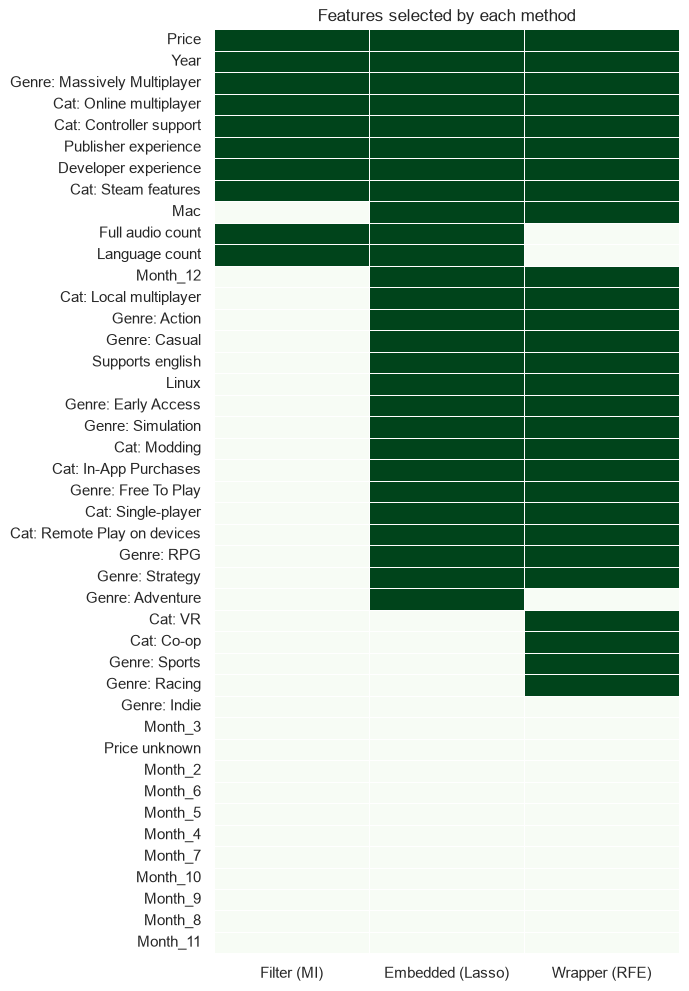

In [120]:
plt.figure(figsize=(6, 12))
sns.heatmap(comparison.drop(columns='Votes'), cmap='Greens', cbar=False, linewidths=0.5)
plt.title('Features selected by each method')
plt.show()

In [121]:
selected_features = comparison[comparison['Votes'] == 3].index.tolist()

X_train_selected = X_train[selected_features]
X_test_selected = X_test[selected_features]

print('Selected by all three methods:', len(selected_features), 'of', X_train.shape[1])
print(selected_features)
print(X_train_selected.shape, X_test_selected.shape)

Selected by all three methods: 8 of 43
['Price', 'Year', 'Genre: Massively Multiplayer', 'Cat: Online multiplayer', 'Cat: Controller support', 'Publisher experience', 'Developer experience', 'Cat: Steam features']
(24048, 8) (6012, 8)


**Final feature set:** only the features chosen by all three methods are kept, so each one is supported by three different kinds of evidence: its own relationship with the target, its usefulness inside a penalised model, and its contribution to cross-validated performance.

- **Kept, 8 of 43:** `Price`, `Year`, `Genre: Massively Multiplayer`, `Developer experience`, `Publisher experience` and three gameplay-feature flags: `Cat: Online multiplayer`, `Cat: Controller support` and `Cat: Steam features`.
- **Dropped:** all month columns, consistent with the finding that release month doesn't matter. `Mac`, `Linux` and `Cat: In-App Purchases` were chosen by Lasso and RFE but scored no higher than noise in the filter, so they are dropped along with every other feature that fewer than three methods chose.

`X_train_selected` and `X_test_selected` are the final training and test features for modelling.

## Section 8: Class Imbalance

This project is a **regression** problem: the target, `Review score`, is a continuous value between 0 and 1, not a set of classes. Class imbalance, stratified splitting and resampling methods such as SMOTE do not apply.

The target's distribution was still checked in Section 5: it is skewed towards high scores (median 0.82, only 5.9% of games below 0.50). This will matter when evaluating models, since errors should be judged against this narrow range.

## Section 9: Limitations

- **Game quality is not in the data.** Only pre-release information is used, so the biggest driver of reviews, how good the game actually is, cannot be measured. The features can explain part of the review score, not all of it.
- **Only games with 50+ reviews.** Most games that never found an audience are filtered out, so the results describe games that reached some players, not the whole Steam catalog.
- **Relationships, not causes.** For example, games with in-app purchases score lower, but this does not prove that adding them would lower a game's score.
- **A snapshot in time.** The data was collected around December 2025. Recent games have had little time to collect reviews, and scores and prices keep changing after collection.

## Section 10: Bonus Work

- **Developer and publisher experience counts (Section 7):** there are thousands of studio names, too many to one-hot encode. Each name is replaced by the number of other games by the same developer or publisher in the training set, which turns a text column into one meaningful number without leakage.
- **Category grouping (Section 4):** Steam's 58 categories, many of them rare or overlapping, are combined into 10 flags that each match a developer decision, such as Co-op or Controller support. This also merges the duplicate labels found in Section 3.
- **Ownership concentration chart (Section 5):** a log-scale chart of all 125,855 games by ownership range shows that success on Steam is concentrated in a tiny number of titles.

## Section 11: Problem Definition

### Type of problem

This is a **regression** problem. The target, `Review score`, is a continuous value between 0 and 1, not a set of classes, so the models predict a number and are judged with MAE, MSE, RMSE and R².

### Target and input features

- **Target (y):** `Review score` = Positive / (Positive + Negative), the share of a game's Steam reviews that are positive.
- **Input features (X):** the 8 features selected by all three methods in Section 7:
  - `Price` and `Year`
  - `Genre: Massively Multiplayer`
  - `Cat: Online multiplayer`, `Cat: Controller support` and `Cat: Steam features`
  - `Developer experience` and `Publisher experience`

All of them are known before release, so the model uses only information a developer has when making decisions.

### What we want to predict and why

The goal is to predict how well players will receive a game from its pre-release decisions, and to see which of those decisions matter most. This tells a developer which choices are linked to better reviews before the game is out.

### Why machine learning is suitable

No simple rule links these features to the review score: their effects are small, they interact, and some are not linear, for example the price sweet spot found in Section 5. Machine learning models can learn these patterns from 24,048 training games and be tested fairly on 6,012 games they have never seen.

## Section 12: Model Training and Cross-Validation

Five models are trained and compared: two linear models, Linear Regression and Ridge, and three tree-based models, Decision Tree, Random Forest and Gradient Boosting. A baseline that always predicts the mean is included as a reference point.

All models use the 8 features selected in Section 7 and are compared with 5-fold cross-validation on the **training set only**. The test set stays untouched until the final evaluation in Section 15.

### Cross-validation setup

The training set is split into 5 equal parts, called folds. Each model is trained on 4 folds and scored on the fifth, and this is repeated 5 times so that every fold is used once for scoring. The 5 scores are then averaged.

- **Why cross-validation:** a single split can be lucky or unlucky. Averaging over 5 folds gives a more reliable comparison, without using the test set.
- **Why `shuffle=True`:** the games are mixed before the folds are made, and `random_state=42` makes the folds the same on every run. The training set is already in random order after `train_test_split`, so this is a safeguard.
- **Train and validation scores:** both are recorded. A model that scores much better on the folds it trained on than on the held-out fold is overfitting.

Each model is scored with MAE, MSE, RMSE and R². scikit-learn reports the three error metrics as negative numbers, because it treats higher as better, so the sign is flipped back before reporting.

In [122]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

#5 folds, shuffled 
folds = KFold(n_splits=5, shuffle=True, random_state=42)


scoring = ['neg_mean_absolute_error', 'neg_mean_squared_error', 'neg_root_mean_squared_error', 'r2']

In [123]:
def evaluate(model):
    # 5-fold cross-validation on the training set, with train scores kept for the overfitting check
    result = cross_validate(model, X_train_selected, y_train, cv=folds,
                            scoring=scoring, return_train_score=True)

    # the error metrics come back negative, so the sign is flipped
    return {
        'CV MAE': -result['test_neg_mean_absolute_error'].mean(),
        'CV MSE': -result['test_neg_mean_squared_error'].mean(),
        'CV RMSE': -result['test_neg_root_mean_squared_error'].mean(),
        'CV R²': result['test_r2'].mean(),
        'CV R² std': result['test_r2'].std(),
        'Train R²': result['train_r2'].mean(),
    }

In [124]:
#checking the function on one model first
evaluate(LinearRegression())

{'CV MAE': np.float64(0.11614843831205542),
 'CV MSE': np.float64(0.021770765257630435),
 'CV RMSE': np.float64(0.14754363554718988),
 'CV R²': np.float64(0.09094945477271636),
 'CV R² std': np.float64(0.007412968040395905),
 'Train R²': np.float64(0.09193351144931536)}

### Models

- **Baseline:** always predicts the average review score of the training set. It is not a real model; it shows what no learning at all looks like, so every other model must beat it.
- **Linear Regression:** fits one weight per feature, so the prediction is a weighted sum of the features. It is simple and easy to interpret, but it can only learn straight-line relationships.
- **Ridge:** Linear Regression with a penalty that keeps the weights small. This makes the model more stable when features are related to each other, at the cost of a slightly simpler fit.
- **Decision Tree:** splits the games with a series of yes/no questions, such as "is the price above 10 USD?", and predicts the average score of each final group. It can learn non-linear patterns, but a deep tree memorises the training data and overfits.
- **Random Forest:** trains many decision trees, each on a random sample of games and features, and averages their predictions. Averaging cancels out much of the overfitting of a single tree.
- **Gradient Boosting:** builds small trees one after another, each one correcting the errors of the trees before it. It usually performs best on tabular data like this, but it has more settings to tune.

In [125]:
models = {
    'Baseline (mean)': DummyRegressor(),
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
}

#cross-validating every model, one row per model
cv_results = {}
for name, model in models.items():
    cv_results[name] = evaluate(model)
    print('Done:', name)

cv_results = pd.DataFrame(cv_results).T
cv_results.round(4)

Done: Baseline (mean)
Done: Linear Regression
Done: Ridge
Done: Decision Tree
Done: Random Forest
Done: Gradient Boosting


,CV MAE,CV MSE,CV RMSE,CV R²,CV R² std,Train R²
Baseline (mean),0.1225,0.0239,0.1548,-0.0000,0.0000,0.0000
Linear Regression,0.1161,0.0218,0.1475,0.0909,0.0074,0.0919
Ridge,0.1161,0.0218,0.1475,0.0909,0.0074,0.0919
Decision Tree,0.1369,0.0330,0.1818,-0.3799,0.0276,0.7745
Random Forest,0.1157,0.0224,0.1498,0.0627,0.0061,0.6971
Gradient Boosting,0.1112,0.0201,0.1416,0.1625,0.0060,0.1796


## Section 13: Model Comparison

The cross-validation results from Section 12 are compared below. Lower MAE, MSE and RMSE are better; higher R² is better. All scores come from the training set only.

In [126]:
#models sorted from best to worst cross-validated R²
comparison_table = cv_results.sort_values('CV R²', ascending=False)
comparison_table.round(4)

,CV MAE,CV MSE,CV RMSE,CV R²,CV R² std,Train R²
Gradient Boosting,0.1112,0.0201,0.1416,0.1625,0.0060,0.1796
Ridge,0.1161,0.0218,0.1475,0.0909,0.0074,0.0919
Linear Regression,0.1161,0.0218,0.1475,0.0909,0.0074,0.0919
Random Forest,0.1157,0.0224,0.1498,0.0627,0.0061,0.6971
Baseline (mean),0.1225,0.0239,0.1548,-0.0000,0.0000,0.0000
Decision Tree,0.1369,0.0330,0.1818,-0.3799,0.0276,0.7745


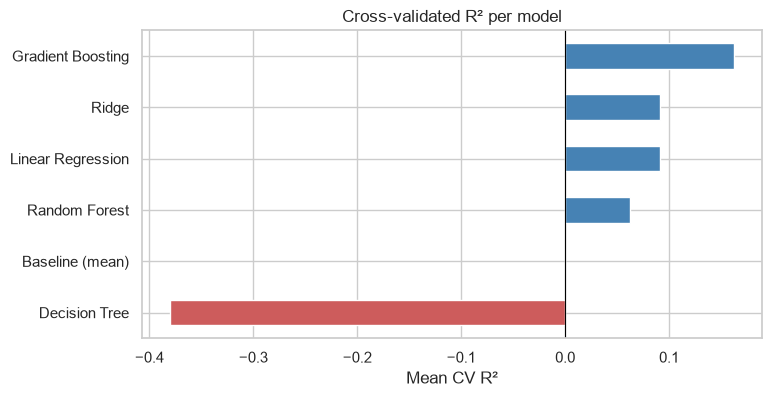

In [127]:
#cross-validated R² of each model, red = worse than the baseline
r2_sorted = cv_results['CV R²'].sort_values()
colors = ['indianred' if value < 0 else 'steelblue' for value in r2_sorted]

r2_sorted.plot(kind='barh', figsize=(8, 4), color=colors, title='Cross-validated R² per model')
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Mean CV R²')
plt.show()

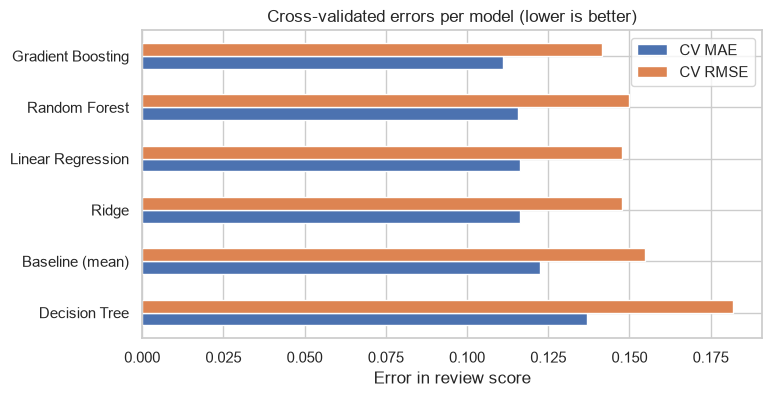

In [128]:
#average errors of each model, lower is better
cv_results[['CV MAE', 'CV RMSE']].sort_values('CV MAE', ascending=False).plot(
    kind='barh', figsize=(8, 4), title='Cross-validated errors per model (lower is better)')
plt.xlabel('Error in review score')
plt.show()

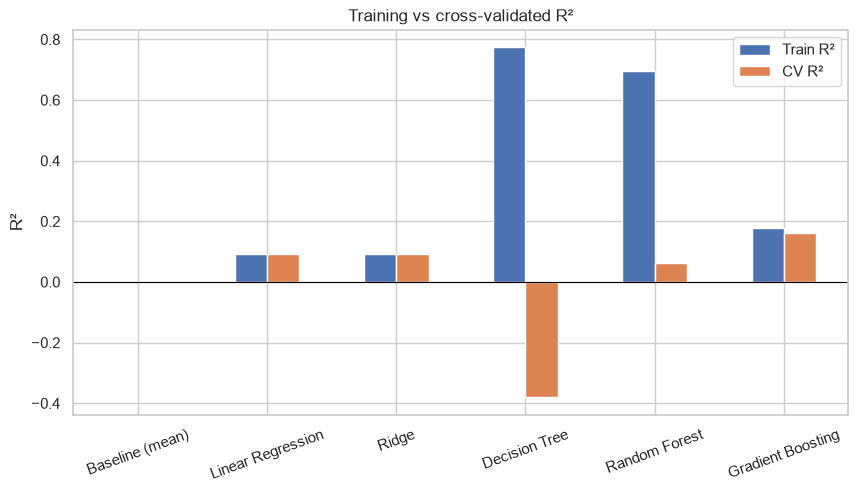

In [129]:
#training R² vs cross-validated R²: a big gap means overfitting
cv_results[['Train R²', 'CV R²']].plot(kind='bar', figsize=(10, 5), title='Training vs cross-validated R²')
plt.axhline(0, color='black', linewidth=0.8)
plt.ylabel('R²')
plt.xticks(rotation=20)
plt.show()

### Best and worst models

- **Best: Gradient Boosting.** It has the highest CV R², 0.163, and the lowest errors, with an MAE of 0.111 against 0.123 for the baseline. Its training R², 0.180, is close to its CV R², so it learns patterns that carry over to new games instead of memorising. It builds many small trees, each fixing the errors of the ones before, so it can capture non-linear effects such as the price sweet spot while each tree stays simple.
- **Worst: Decision Tree.** Its CV R² is −0.380, which is worse than always predicting the average, even though its training R² is 0.775. With no depth limit, the tree keeps splitting until it fits individual games, so it memorises noise that does not carry over to new games. This is clear **overfitting**.
- **Random Forest also overfits:** 0.697 on the training folds against 0.063 in cross-validation, slightly below Linear Regression. Averaging many trees is far better than a single tree, but with default settings every tree still grows fully deep. Limiting the depth of the trees is a natural candidate for tuning in Section 14.
- **Linear Regression and Ridge are identical,** with a CV R² of 0.091. With only 8 features and 24,048 games, the weights are already stable, so Ridge's penalty has nothing to fix. Their training and CV scores match, so they **underfit** rather than overfit: a straight-line model is too simple for the patterns in the data.
- **The differences are real:** the standard deviation of CV R² across the 5 folds is below 0.01 for every model except the Decision Tree, much smaller than the gaps between the models.

All models except the Decision Tree beat the baseline. The R² values stay low overall because, as noted in Section 9, the quality of the game itself is not in the data.

## Section 14: Hyperparameter Tuning

Hyperparameters are settings chosen before training, such as how deep each tree may grow. They are not learned from the data, so different values are tried and compared.

Two models are tuned:
- **Random Forest:** it overfits badly with default settings, so tuning should show whether limiting the trees fixes it.
- **Gradient Boosting:** it is already the best model, so tuning it gives the strongest candidate for the final evaluation in Section 15.

**Method:** `RandomizedSearchCV` tries 20 random combinations from a grid of values for each model. Every combination is scored with the same 5 folds as Section 12, using R², on the **training set only**. Trying 20 random combinations covers the grid well at a fraction of the time of trying every one.

### Tuning Random Forest

Parameters adjusted:
- `max_depth`: how many levels of questions each tree may ask. Shallower trees cannot memorise individual games.
- `min_samples_leaf`: the fewest games allowed in a final group. Larger groups give more stable averages.
- `max_features`: how many features each split may look at. Fewer features make the trees more different from each other, which helps the averaging.
- `n_estimators`: how many trees are averaged.

In [130]:
from sklearn.model_selection import RandomizedSearchCV

rf_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [4, 6, 8, 10, 12, None],
    'min_samples_leaf': [1, 5, 10, 20, 50],
    'max_features': ['sqrt', 0.5, 1.0],
}

rf_search = RandomizedSearchCV(RandomForestRegressor(random_state=42), rf_grid, n_iter=20,
                               cv=folds, scoring='r2', random_state=42, n_jobs=-1)
rf_search.fit(X_train_selected, y_train)

print('Best parameters:', rf_search.best_params_)
print('Best CV R²     :', round(rf_search.best_score_, 4))

Best parameters: {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 12}
Best CV R²     : 0.1724


### Tuning Gradient Boosting

Parameters adjusted:
- `n_estimators`: how many small trees are built one after another.
- `learning_rate`: how much each new tree is allowed to correct. A smaller rate learns more carefully but needs more trees.
- `max_depth`: how complex each small tree may be.
- `min_samples_leaf`: the fewest games allowed in a final group.
- `subsample`: the share of games each tree is trained on. Using less than all of them adds randomness that reduces overfitting.

In [131]:
gb_grid = {
    'n_estimators': [100, 200, 300, 500],
    'learning_rate': [0.02, 0.05, 0.1],
    'max_depth': [2, 3, 4, 5],
    'min_samples_leaf': [1, 10, 20, 50],
    'subsample': [0.8, 1.0],
}

gb_search = RandomizedSearchCV(GradientBoostingRegressor(random_state=42), gb_grid, n_iter=20,
                               cv=folds, scoring='r2', random_state=42, n_jobs=-1)
gb_search.fit(X_train_selected, y_train)

print('Best parameters:', gb_search.best_params_)
print('Best CV R²     :', round(gb_search.best_score_, 4))

Best parameters: {'subsample': 0.8, 'n_estimators': 500, 'min_samples_leaf': 10, 'max_depth': 5, 'learning_rate': 0.05}
Best CV R²     : 0.1941


### Before and after tuning

The tuned models are cross-validated again with the `evaluate` function from Section 12, so they are scored on exactly the same folds and metrics as the default models.

In [132]:
#default models from Section 12 next to the tuned ones
tuned_results = pd.DataFrame({
    'Random Forest (default)': cv_results.loc['Random Forest'],
    'Random Forest (tuned)': evaluate(rf_search.best_estimator_),
    'Gradient Boosting (default)': cv_results.loc['Gradient Boosting'],
    'Gradient Boosting (tuned)': evaluate(gb_search.best_estimator_),
}).T

tuned_results.round(4)

,CV MAE,CV MSE,CV RMSE,CV R²,CV R² std,Train R²
Random Forest (default),0.1157,0.0224,0.1498,0.0627,0.0061,0.6971
Random Forest (tuned),0.1099,0.0198,0.1408,0.1724,0.0082,0.3837
Gradient Boosting (default),0.1112,0.0201,0.1416,0.1625,0.0060,0.1796
Gradient Boosting (tuned),0.1083,0.0193,0.1389,0.1941,0.0049,0.2993


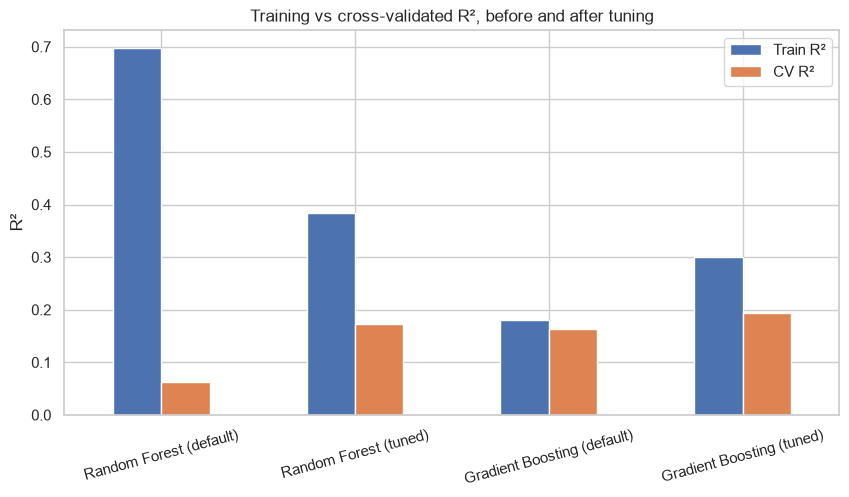

In [133]:
#a smaller gap between the two bars means less overfitting
tuned_results[['Train R²', 'CV R²']].plot(kind='bar', figsize=(10, 5), title='Training vs cross-validated R², before and after tuning')
plt.ylabel('R²')
plt.xticks(rotation=15)
plt.show()

### Did tuning help?

Yes, both models improved on every metric.

- **Random Forest improved the most:** CV R² rose from 0.063 to 0.172 and MAE fell from 0.1157 to 0.1099. The best settings were `max_depth` 12, `max_features` 0.5, `min_samples_leaf` 1 and 200 trees. Limiting the depth and letting each split look at only half of the features cut the training R² from 0.697 to 0.384, so the trees memorise far less. A gap between training and CV scores remains, so it still overfits somewhat.
- **Gradient Boosting improved less, from an already good start:** CV R² rose from 0.163 to 0.194 and MAE fell from 0.1112 to 0.1083. The best settings were 500 trees, `learning_rate` 0.05, `max_depth` 5, `min_samples_leaf` 10 and `subsample` 0.8. More, slightly deeper trees with a smaller learning rate let it learn more detail, while `subsample` and `min_samples_leaf` keep it in check. Its training R² rose to 0.299, a gap of about 0.10, which is a mild sign of overfitting; the cross-validated score, which is what matters for new games, still improved.
- **Grid edges:** two of Gradient Boosting's best values, 500 trees and depth 5, are the largest in the grid, so a wider grid might gain a little more. The gains from tuning are already small, so the current settings are kept.

**Selected model:** the tuned Gradient Boosting model has the highest CV R² and the lowest errors of all the models, so it is the one evaluated on the untouched test set in Section 15.

## Section 15: Final Evaluation and Discussion

The final model is the **tuned Gradient Boosting** model from Section 14. `RandomizedSearchCV` has already refitted it on the full training set with the best settings.

It is now evaluated **once** on the test set, the 6,012 games that were set aside in Section 6 and never used for training, cross-validation, model selection or tuning. This gives an honest estimate of how the model performs on games it has never seen. The baseline is scored on the same test set for reference.

In [134]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

final_model = gb_search.best_estimator_
y_pred = final_model.predict(X_test_selected)

#baseline for reference: always predicts the training mean
baseline = DummyRegressor().fit(X_train_selected, y_train)
y_base = baseline.predict(X_test_selected)

def test_scores(y_true, y_hat):
    return {'MAE': mean_absolute_error(y_true, y_hat),
            'MSE': mean_squared_error(y_true, y_hat),
            'RMSE': root_mean_squared_error(y_true, y_hat),
            'R²': r2_score(y_true, y_hat)}

final_results = pd.DataFrame({
    'Baseline (test set)': test_scores(y_test, y_base),
    'Tuned Gradient Boosting (CV on training set)': {'MAE': tuned_results.loc['Gradient Boosting (tuned)', 'CV MAE'],
                                                     'MSE': tuned_results.loc['Gradient Boosting (tuned)', 'CV MSE'],
                                                     'RMSE': tuned_results.loc['Gradient Boosting (tuned)', 'CV RMSE'],
                                                     'R²': tuned_results.loc['Gradient Boosting (tuned)', 'CV R²']},
    'Tuned Gradient Boosting (test set)': test_scores(y_test, y_pred),
}).T

final_results.round(4)

,MAE,MSE,RMSE,R²
Baseline (test set),0.1216,0.0237,0.1540,-0.0002
Tuned Gradient Boosting (CV on training set),0.1083,0.0193,0.1389,0.1941
Tuned Gradient Boosting (test set),0.1106,0.0200,0.1414,0.1566


### Predictions vs actual scores

The left chart compares each test game's predicted score with its real score; a perfect model would put every point on the red line. The right chart shows the errors, actual minus predicted.

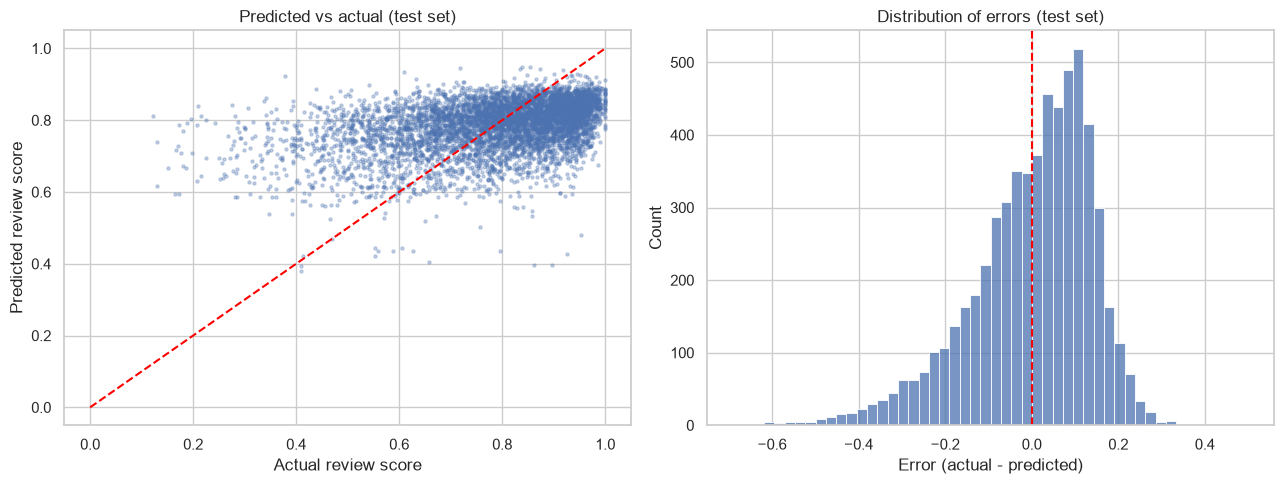

Range of actual scores   : 0.123 to 1.0
Range of predicted scores: 0.381 to 0.949


In [135]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].scatter(y_test, y_pred, s=5, alpha=0.3)
ax[0].plot([0, 1], [0, 1], color='red', linestyle='--')
ax[0].set_xlabel('Actual review score')
ax[0].set_ylabel('Predicted review score')
ax[0].set_title('Predicted vs actual (test set)')

sns.histplot(y_test - y_pred, bins=50, ax=ax[1])
ax[1].axvline(0, color='red', linestyle='--')
ax[1].set_xlabel('Error (actual - predicted)')
ax[1].set_title('Distribution of errors (test set)')

plt.tight_layout()
plt.show()

print('Range of actual scores   :', round(y_test.min(), 3), 'to', round(y_test.max(), 3))
print('Range of predicted scores:', round(y_pred.min(), 3), 'to', round(y_pred.max(), 3))

### Which features the model relies on

Gradient Boosting reports how much each feature reduced the error across all its splits. This links the model back to the problem statement: which pre-release decisions matter most.

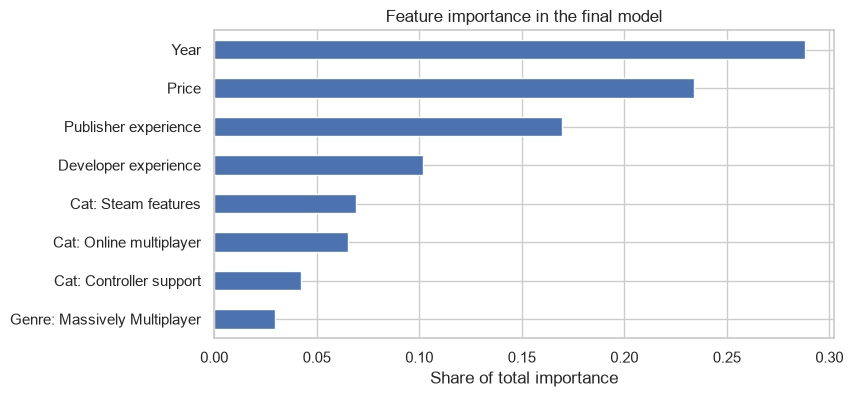

Year                            0.288
Price                           0.234
Publisher experience            0.170
Developer experience            0.102
Cat: Steam features             0.069
Cat: Online multiplayer         0.065
Cat: Controller support         0.042
Genre: Massively Multiplayer    0.030
dtype: float64

In [136]:
importances = pd.Series(final_model.feature_importances_, index=X_train_selected.columns).sort_values()

importances.plot(kind='barh', figsize=(8, 4), title='Feature importance in the final model')
plt.xlabel('Share of total importance')
plt.show()

importances.sort_values(ascending=False).round(3)

### Results and discussion

**Final performance on the test set:** the tuned Gradient Boosting model reaches an MAE of 0.111, an RMSE of 0.141 and an R² of 0.157 on the 6,012 unseen games. The baseline, which always predicts the average, has an MAE of 0.122 and an R² of 0. The model clearly beats it, but it explains only a modest part of the variation in review scores.

**Which model performed best and worst?**
- **Best:** tuned Gradient Boosting, with a CV R² of 0.194, ahead of tuned Random Forest at 0.172.
- **Worst:** the default Decision Tree, with a CV R² of −0.380, worse than predicting the average.

**Why did the models produce different results?**
- **Linear models** can only learn straight-line effects, so they miss patterns such as the price sweet spot from Section 5, where both cheap and expensive games score lower.
- **A single deep tree** memorises the training games, so its rules do not carry over to new ones.
- **Random Forest** averages many trees, which cancels much of that memorising, and **Gradient Boosting** builds small trees that each correct the last, so both can learn non-linear effects while staying general.

**Did hyperparameter tuning improve performance?** Yes. Random Forest's CV R² rose from 0.063 to 0.172, mainly by limiting tree depth, and Gradient Boosting's from 0.163 to 0.194.

**Did we observe overfitting or underfitting?**
- **Overfitting:** the default Decision Tree and Random Forest scored far higher on the training folds than in cross-validation. Tuning reduced this for Random Forest.
- **Underfitting:** Linear Regression and Ridge scored the same low R² on training and validation data, so they are too simple for these patterns.
- **The final model:** its test R², 0.157, is a little lower than its CV R², 0.194. Part of this is expected, because the best of 20 settings was chosen by its CV score, which flatters that score slightly. The gap is small, so the model is not seriously overfitting.

**Which features matter most?** Release year, price, and publisher and developer experience carry about 80% of the model's importance. The gameplay flags and the Massively Multiplayer genre add smaller contributions. This answers the problem statement: when and at what price a game is released, and who makes it, are the pre-release factors most linked to its reviews.

**Limitations of the final model:**
- **It plays it safe:** predictions only range from 0.38 to 0.95, while real scores range from 0.12 to 1.0. The model rarely predicts very low scores, so its biggest errors are badly received games that it expected to do well, the long left tail of the error chart.
- **Game quality is not in the data:** only pre-release information is used, so the biggest driver of reviews cannot be captured, as noted in Section 9.
- **Relationships, not causes:** a feature being important does not mean changing it would change a game's score.
- **Limited scope:** the model only covers games with 50+ reviews, and the developer and publisher counts were computed once on the whole training set, so cross-validation scores may be very slightly optimistic.